# Partea 3.2 Transformer - stilometry fusion

In [1]:
import pandas as pd
import re
from sklearn.preprocessing import StandardScaler, LabelEncoder
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer
import torch.nn as nn
from transformers import AutoModel
from transformers import get_linear_schedule_with_warmup
from torch.optim import AdamW
from sklearn.metrics import f1_score, accuracy_score
import torch
import numpy as np
import random

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from collections import Counter
import unicodedata
import os

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device {device}")

Device cuda


In [3]:
# FUNCTII UTILE le definim sus
def drop_columns(df, columns_to_drop):
    return df.drop(columns=columns_to_drop)

# avem o problema la moldova
# diacriticele aparent nu sunt unicode?
def clean_text(text):
    if not isinstance(text, str):
        return ""
    
    text = unicodedata.normalize("NFC", text)

    # remove combining chars, deci t de la tap nu va mai avea caciulita sepaarata va fi un singur char
    text = ''.join(c for c in text if not unicodedata.combining(c))

    text = text.replace("„", '"').replace("”", '"')
    text = text.replace("’", "'")

    # remove control chars
    text = ''.join(c for c in text if unicodedata.category(c)[0] != 'C')

    text = text.replace("\n", " ")
    text = text.replace('""', '"')
    text = re.sub(r"\s+", " ", text)
        
    return text.strip()


def count_unk(texts, tokenizer, n=100):
    total_unk = 0
    total_tokens = 0

    for t in texts[:n]:
        enc = tokenizer(
            t,
            truncation=True,
            max_length=512
        )

        input_ids = enc["input_ids"]
        total_tokens += len(input_ids)

        unk_id = tokenizer.unk_token_id
        total_unk += sum(1 for x in input_ids if x == unk_id)

    return total_unk / total_tokens


def count_unk_absolute(texts, tokenizer, n=100):
    total_unk = 0
    for t in texts[:n]:
        enc = tokenizer(t, truncation=True, max_length=512)
        unk_id = tokenizer.unk_token_id
        total_unk += sum(1 for x in enc["input_ids"] if x == unk_id)
    return total_unk


def count_combining(texts, n=1000):
    count = 0
    for t in texts[:n]:
        if any(unicodedata.combining(c) for c in t):
            count += 1
    return count


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [4]:
# punem asta in functie!!

STYLO_FEATURES = [
    # stylo basic
    'stylo_avg_word_length', 'stylo_std_word_length',
    'stylo_avg_sentence_length', 'stylo_std_sentence_length',
    'stylo_sentence_count', 'stylo_hapax_rate',
    'stylo_punctuation_rate', 'stylo_question_rate',
    'stylo_exclamation_rate', 'stylo_lexical_diversity',
    'stylo_noun_ratio', 'stylo_verb_ratio',
    'stylo_adj_ratio', 'stylo_adv_ratio',
    'stylo_pron_ratio', 'stylo_det_ratio',
    'stylo_aux_ratio',
    # advanced
    'adv_prep_rate', 'adv_conj_rate', 'adv_pron_rate',
    'adv_art_rate', 'adv_aux_rate', 'adv_transition_rate',
    'adv_word_repetition_rate', 'adv_flesch_ro',
    'adv_gunning_fog', 'adv_mttr', 'adv_mtld', 'adv_unique_bigram_rate',
    'adv_unique_trigram_rate', 'adv_diacritic_ratio',
    'adv_suffix_rate', 'adv_uppercase_words_rate'
]

# # scalerul se face FIT doar pe train
# scaler = StandardScaler()

# X_stylo_train = scaler.fit_transform(
#     top20_ro_train_text[STYLO_FEATURES].fillna(0)
# )
# X_stylo_val  = scaler.transform(
#     top20_ro_val_text[STYLO_FEATURES].fillna(0)
# )
# X_stylo_test = scaler.transform(
#     top20_ro_test_text[STYLO_FEATURES].fillna(0)
# )

# n_stylo_features = X_stylo_train.shape[1]
# print(f"Nr features stilometrice: {n_stylo_features}")

In [5]:
tokenizer = AutoTokenizer.from_pretrained("dumitrescustefan/bert-base-romanian-cased-v1")

In [6]:
class AuthorDatasetFusion(Dataset):
    def __init__(self, texts, labels, stylo_features, 
                 tokenizer, max_length=512, overlap=0.1):
        self.texts          = texts
        self.labels         = labels
        self.stylo_features = stylo_features  # numpy array
        self.tokenizer      = tokenizer
        self.max_length     = max_length
        self.stride         = int(max_length * (1 - overlap))
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        text        = self.texts[idx]
        label       = self.labels[idx]
        stylo_feats = self.stylo_features[idx]
        
        encoded = self.tokenizer(
            text,
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        
        return {
            'input_ids':      encoded['input_ids'].squeeze(0),
            'attention_mask': encoded['attention_mask'].squeeze(0),
            'stylo_features': torch.tensor(
                stylo_feats, dtype=torch.float32
            ),
            'label': torch.tensor(label, dtype=torch.long)
        }


In [7]:
def build_dataloaders_fusion(train_df, val_df, test_df,
                              tokenizer, stylo_features_cols,
                              batch_size=8, seed=42):
    le = LabelEncoder()
    le.fit(train_df['author'])

    y_train = le.transform(train_df['author'])
    y_val   = le.transform(val_df['author'])
    y_test  = le.transform(test_df['author'])

    print(f"Autori: {le.classes_}")

    texts_train = train_df['text'].tolist()
    texts_val   = val_df['text'].tolist()
    texts_test  = test_df['text'].tolist()

    print("\n[DEBUG] Combining chars BEFORE clean:")
    print("Train combining:", count_combining(texts_train))
    print("Val   combining:", count_combining(texts_val))
    print("Test  combining:", count_combining(texts_test))

    texts_train = train_df['text'].apply(clean_text).tolist()
    texts_val   = val_df['text'].apply(clean_text).tolist()
    texts_test  = test_df['text'].apply(clean_text).tolist()

    print("\n[DEBUG] UNK check:")
    print("Train UNK:", count_unk_absolute(texts_train, tokenizer))
    print("Val   UNK:", count_unk_absolute(texts_val, tokenizer))
    print("Test  UNK:", count_unk_absolute(texts_test, tokenizer))

    print("\n[DEBUG] Combining chars AFTER clean:")
    print("Train combining:", count_combining(texts_train))
    print("Val   combining:", count_combining(texts_val))
    print("Test  combining:", count_combining(texts_test))
    

    scaler      = StandardScaler()
    X_train     = scaler.fit_transform(train_df[stylo_features_cols].fillna(0))
    X_val       = scaler.transform(val_df[stylo_features_cols].fillna(0))
    X_test      = scaler.transform(test_df[stylo_features_cols].fillna(0))

    train_ds = AuthorDatasetFusion(texts_train, y_train, X_train, tokenizer)
    val_ds   = AuthorDatasetFusion(texts_val,   y_val,   X_val,   tokenizer)
    test_ds  = AuthorDatasetFusion(texts_test,  y_test,  X_test,  tokenizer)

    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(train_ds, batch_size=batch_size,
                              shuffle=True,  num_workers=4,
                              pin_memory=True, generator=generator)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size,
                              shuffle=False, num_workers=4, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size,
                              shuffle=False, num_workers=4, pin_memory=True)

    print(f"Autori: {len(le.classes_)} | Stylo features: {X_train.shape[1]}")

    return train_loader, val_loader, test_loader, le, texts_test, y_test, X_test


- initiem clasa transformerului 
- bert lucreaza direct pe text nu stie sa extraga sau sa lucreze cu stilometria mea
- de aceaa pe langa parametrii lui bert
- vom mai avea o mica retea care prelucreaza semnalul stilometriei
- bert scuipa un vector de dimensiune 768 pt fiecare text
- un autor va fi un tensor de acesti vectori [CLS]
- Nu putem lucra cu matrice incompatibile ca dimensiune (eu am un vector de 33 de features iar bert are 768)
- Stilometria va fi prelucrata de un MLP , adica vom avea un vector rezultat de o alta dimensiune 
- Abia acum concatenam cu ce am obtinut de la bert
- mai trec printr-un MLP features din bert + ce am scos din MLP stilo 
- fac predictia abia acum

[TEXT] ─> BERT ─>(768) <br>
                       \
                        CONCAT ─> FUSION ─> CLASSIFIER
                       /<br>
<br>[STYLO] ─> MLP ─> (64)

De ce folsesc un MLP ca sa prelucrez stilometria? Pentru ca dupa cum am vazut la shallow models, stilometria neprelucrata nu propaga cum trebuie vreun semnal pe care il pot folosi sa disting intre autori (plus ca nu pot scoate un numar nelimitat de stilometrii aici chiar este o limita reala). Cu MLP putem sa invatam relatii, sa reducem din zgomot, si sa scoatem un vector embedding intermediar mult mai informativ decat stand alone stylometric features.

Cum construim totusi clasa care foloseste BERT? Trebyie sa intelegem un pic cum functioneaza BERT si sa stim ce scoatem din el
[link1_medium](https://medium.com/data-and-beyond/complete-guide-to-building-bert-model-from-sratch-3e6562228891)

1. BERT tokenizeaza textul nu lucreaza cu el brut (asa ca da il ajuti daca cureti mizeriile inainte)
2. Cu WordPiece rezlta : `[CLS] cuvant1 cuvant2 ... cuvantN [SEP]`. A tokenized BERT input always starts with a special [CLS] token and ends with a special [SEP] token. CLS stands for classification. It serves as the the Start of Sentence (SOS) and represent the meaning of the entire sentence. SEP serves as End of Sentence (EOS) and also the separation token between first and second sentences.

ASTA CU MLP FACE SEFU MARE EU O SA SCOT ACEL MLP TAMPIT SI IL BAG DIRECT ASA CUM E 



In [8]:
# class BERTWithStylometry(nn.Module):
#     # de ce folosim nn.Module?
#     # pentru ca backbone la torch.nn
#     # fiecare model din pytroch este de fapt o subclasa nn.Module
#     # Module abstractizeaza deifinirea layerelor, forward si backward. Adica stie sa inmulteasca matrice pe scurt :)
#     # si se ocupa si de parametrii , optimizator , scheduler, d-aia poti sa ii si salvezi usor
#     def __init__(self, num_authors, no_stylo_features, dropout=0.2):
#         super(BERTWithStylometry,self).__init__()
#         # ok avem sablonul pe Module
#         # ce componente avem? tokenizer (encoder bert), reteaua intermediara ('encoder' MLP) si reteaua finala (MLP)
#         # 1. self.bert
#         # 2. self.bert_dropout
#         # 3. self.stylo_network
#         # 4. self.fusion
#         # 5. self.classifier
#         self.bert = AutoModel.from_pretrained("dumitrescustefan/bert-base-romanian-cased-v1")
        
#         # ca la orice retea se aplica dropout dar vom diferentia de data asta pentru ca dropout rate va exista si la MLP
#         # bert are deja un dropout intern la encoder dar asta al nostru se aplica doar pe embeddingul final adica CLS
#         # teoretic nu e obligatoriu dar e good practice
#         self.bert_dropout = nn.Dropout(dropout)

#         # definim mini reteaua de stilo
#         # ne reamintim de la tema 2 IA: facem stack la mai multe straturi cu Sequential
#         # si descriem exact cum arata arhitectura
#         self.stylo_network = nn.Sequential(
#             # dim input -> dim strat 1
#             nn.Linear(no_stylo_features, 128),
#             # linear activation
#             nn.ReLU(),
#             # dropout
#             nn.Dropout(0.2),
#             # strat iesire
#             nn.Linear(128,64),
#             nn.ReLU(),
#             nn.Dropout(0.1) # din experienta nu punem valori mari aici
#         )

#         # ok acum definim mlp pt fusion
#         # trebuie concatenate? 
#         # nu cred ca aici dar trb sa stim straturile si dropout
#         # [semantic + stil] -> reprezentare combinata
#         # in_dim: 768 (bert CLS) + 64 (Stilo MLP) = 832
#         # folosim dropout de la CLS
#         self.fusion = nn.Sequential(
#             nn.Linear(832, 256),
#             nn.ReLU(),
#             nn.Dropout(dropout),

#             nn.Linear(256, 128),
#             nn.ReLU(),
#             nn.Dropout(dropout)
#         )

#         # clasificatorul final 
#         self.classifier = nn.Linear(128, num_authors)

#     # ne uitam cum am definit inputul in Dataset
#     # input id: textul cu tokeni cu embeddinguri
#     # attention mask calculata de bert -> matrice binara deci un vector pt fiecare text?
#     # 1 atentie pe acel token 0 il ignori
#     # ambele au shape [B, L]  batch_size, max_length (512)
#     # nu folosim labels aici , mai intai forward pass calculeaza scoruri brute (logits)
#     # label = y este folosit in loss!
#     def forward(self, input_ids, attention_mask, stylo_features):
#         # scoatem logits (B, num_authors)

#         # pas 1: trecem textul prin bert
#         bert_output = self.bert(input_ids=input_ids, attention_mask=attention_mask)

#         # pas 2 extrag reprezentarea globala adica tokenul CLS (B, 768)
#         # cum accesez tensorul din obiect? cu atributul last hidden stat
#         cls_token = bert_output.last_hidden_state[:,0,:]

#         # pas 3: regularizare pt overfit
#         # pe ce tensor? tot pe cls
#         cls_token = self.bert_dropout(cls_token)

#         # pas 4: procesez stilometria scoatem (B, 64)
#         stylo_out = self.stylo_network(stylo_features)

#         # pas 5 concatenam CLS cu stylo (B, 832)
#         concatenated_output = torch.cat([cls_token, stylo_out], dim=1) # dim e ca axis pt tensori

#         # pas 6: MLP fusion => (B, 128)
#         fusion_output = self.fusion(concatenated_output)

#         # pas 7: clasificarea propriu zzisa logits = (B, num_authors)
#         logits = self.classifier(fusion_output)

#         return logits

NEW MODEL

In [8]:
def mean_pooling(bert_output, attention_mask):
    token_embeddings = bert_output.last_hidden_state  # (B, L, 768)
    mask_expanded    = attention_mask.unsqueeze(-1).float()  # (B, L, 1)
    sum_embeddings   = torch.sum(token_embeddings * mask_expanded, dim=1)  # (B, 768)
    sum_mask         = torch.clamp(mask_expanded.sum(dim=1), min=1e-9)     # (B, 1)
    return sum_embeddings / sum_mask  # (B, 768)

In [8]:
class BERTWithStylometry(nn.Module):
    # de ce folosim nn.Module?
    # pentru ca backbone la torch.nn
    # fiecare model din pytroch este de fapt o subclasa nn.Module
    # Module abstractizeaza deifinirea layerelor, forward si backward. Adica stie sa inmulteasca matrice pe scurt :)
    # si se ocupa si de parametrii , optimizator , scheduler, d-aia poti sa ii si salvezi usor
    def __init__(self, num_authors, no_stylo_features, dropout=0.2):
        super(BERTWithStylometry,self).__init__()
        # ok avem sablonul pe Module
        # ce componente avem? tokenizer (encoder bert), reteaua intermediara ('encoder' MLP) si reteaua finala (MLP)
        # 1. self.bert
        # 2. self.bert_dropout
        # 3. self.stylo_network
        # 4. self.fusion
        # 5. self.classifier
        self.bert = AutoModel.from_pretrained("dumitrescustefan/bert-base-romanian-cased-v1")
        
        # ca la orice retea se aplica dropout dar vom diferentia de data asta pentru ca dropout rate va exista si la MLP
        # bert are deja un dropout intern la encoder dar asta al nostru se aplica doar pe embeddingul final adica CLS
        # teoretic nu e obligatoriu dar e good practice
        self.bert_dropout = nn.Dropout(dropout)

        # ok acum definim mlp pt fusion
        # trebuie concatenate? 
        # nu cred ca aici dar trb sa stim straturile si dropout
        # [semantic + stil] -> reprezentare combinata
        # in_dim: 768 (bert CLS) + 64 (Stilo MLP) = 832
        # folosim dropout de la CLS
        self.fusion = nn.Sequential(
            nn.Linear(768 + no_stylo_features, 256),
            nn.LayerNorm(256),   # - in loc de ReLU direct
            nn.GELU(),           # - GELU in loc de ReLU
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        # clasificatorul final 
        self.classifier = nn.Linear(128, num_authors)

    # ne uitam cum am definit inputul in Dataset
    # input id: textul cu tokeni cu embeddinguri
    # attention mask calculata de bert -> matrice binara deci un vector pt fiecare text?
    # 1 atentie pe acel token 0 il ignori
    # ambele au shape [B, L]  batch_size, max_length (512)
    # nu folosim labels aici , mai intai forward pass calculeaza scoruri brute (logits)
    # label = y este folosit in loss!
    def forward(self, input_ids, attention_mask, stylo_features):
        bert_output = self.bert(input_ids=input_ids,
                                attention_mask=attention_mask)
        
        # mean pooling in loc de CLS
        # pooled = mean_pooling(bert_output, attention_mask)  # (B, 768)
        pooled = bert_output.last_hidden_state[:, 0, :]  # (B, 768) - CLS token
        pooled = self.bert_dropout(pooled)
        
        # concatenare directa fara MLP intermediar
        concatenated = torch.cat([pooled, stylo_features], dim=1)  # (B, 803)
        
        fusion_output = self.fusion(concatenated)   # (B, 128)
        logits        = self.classifier(fusion_output)  # (B, num_authors)
        return logits
    


Train: 

```
for batch in loader: 
    move to device
    forward
    loss
    backward
    optimizer.step()
    scheduler.step()
```

- si toate astea : `input_ids , attention_mask, stylo_features, label` trebuie puse pe gpu!

In [10]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device {device}")

Device cuda


In [9]:
def train_epoch_fusion(model, loader, optimizer, scheduler, criterion, device):
    # de fapt train punem separat :)
    """
    def train_epoch(...):
    model.train()

    for batch in loader:
        move to device

        optimizer.zero_grad()

        logits = model(...)
        loss = ...

        loss.backward()
        clip_grad

        optimizer.step()
        scheduler.step()
    """
    model.train()
    total_loss = 0.0

    for i, batch in enumerate(loader):
        input_ids = batch['input_ids'].to(device, non_blocking=True)
        attention_mask = batch['attention_mask'].to(device, non_blocking=True)
        stylo_features = batch['stylo_features'].to(device, non_blocking=True)
        labels = batch['label'].to(device, non_blocking=True)

        # initiem graienti cu 0
        optimizer.zero_grad(set_to_none=True)
        logits = model(input_ids, attention_mask, stylo_features)
        loss = criterion(logits, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

        if i % 100 == 0:
            print(f"  Batch {i}/{len(loader)} loss: {loss.item():.4f}")
        
    return total_loss / len(loader)


def eval_epoch_fusion(model, loader, criterion, device):
    # forward + metrics
    # dezactivam dropout
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []

    # oprim gradient computation
    with torch.no_grad():
        for batch in loader:
            # punem pe device
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            stylo_features = batch['stylo_features'].to(device, non_blocking=True)
            labels = batch['label'].to(device, non_blocking=True)

            # forward
            logits = model(input_ids, attention_mask, stylo_features)
            loss = criterion(logits, labels)

            # extrag predictia cea mai buna din fiecare tensor
            # de ce argmax si de ce dim=-1?? (B, num_classes) automat -1 ia num_classes
            preds = torch.argmax(logits, dim=-1)

            total_loss += loss.item()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    f1 = f1_score(all_labels,all_preds, average='macro')
    acc = accuracy_score(all_labels, all_preds)

    return total_loss / len(loader), f1, acc


def predict_with_voting_fusion(model, text, stylo_vector, tokenizer, device, max_length=512, overlap=0.1):
    # text lung > 512 token?
    # il impartim in ferestre de 512 token
    # stride = 512 * (1 - 0.1) ≈ 460 
    #[0:512] , [460:972], [920:1432]
    stride = int(max_length * (1 - overlap))
    model.eval()

    # nu truncam textul il vrem pe tot aici 
    tokens = tokenizer(text, truncation=False, add_special_tokens=True, return_tensors='pt')
    # scoatem tokenii
    input_ids = tokens['input_ids'][0]
    
    # scoatem tensor din stylo features deci folosim unsqueeze ->(1, L)
    stylo_tensor =torch.tensor(
        stylo_vector, dtype=torch.float32
    ).unsqueeze(0).to(device)
    predictions =[]

    with torch.no_grad():
        # parcurgem textul pe ferestre
        for start in range(0, len(input_ids), stride):
            # luam fereastra curenta, avem grija ca poate sa fie mai mica ca 512
            end = min(start + max_length, len(input_ids))
            window = input_ids[start:end]

            # padding in caz ca e mai mica, de la len(window) -> 512 
            if len(window) < max_length:
                padding = torch.zeros(max_length - len(window), dtype=torch.long)
                # concatenam
                window = torch.cat([window, padding])
            
            # punem 1 doar pe tokenii nepadati adica cei diferiti de 0
            attn_mask = (window != 0).long()

            # cum integram si stilometria?
            # stilometria e calculata pe intreg documentul 
            # deci am acelasi vector pt toate ferestrele
            logits = model(
                window.unsqueeze(0).to(device),
                attn_mask.unsqueeze(0).to(device),
                stylo_tensor
            )

            pred = torch.argmax(logits, dim=-1).item()
            predictions.append(pred)

            if end == len(input_ids):
                break # gata secventa
    # scoatem cea mai frecventa predictie 
    # Counter returneaza un dictionar cu key = predictia , val = de cate ori apare predictia
    counter_dict = Counter(predictions)
    return counter_dict.most_common(1)[0][0]
        

def evaluate_with_voting(texts, y_true, X_stylo, tokenizer, label_encoder, device, dataset_name="", model_path=None):

    num_authors = len(np.unique(y_true))
    num_stylo_features = X_stylo.shape[1]
    
    model = BERTWithStylometry(
        num_authors=num_authors, 
        no_stylo_features=num_stylo_features
    ).to(device)

    
    if model_path is not None:
        model.load_state_dict(torch.load(model_path, map_location=device))
        print(f"Incarcat best model din {model_path}")

    print(f"\nEvaluare fusion cu majority voting — {dataset_name}")

    all_preds = []
    for i, (text, stylo_vec) in enumerate(zip(texts, X_stylo)):
        pred = predict_with_voting_fusion(
            model, text, stylo_vec, tokenizer, device
        )
        all_preds.append(pred)
        if i % 100 == 0:
            print(f"  {i}/{len(texts)}")

    f1  = f1_score(y_true, all_preds, average='macro')
    acc = (np.array(all_preds) == np.array(y_true)).mean()

    print(f"\nTest F1 macro: {f1:.4f} | Accuracy: {acc:.4f}")
    print(classification_report(
        y_true, all_preds,
        target_names=label_encoder.classes_
    ))

    return all_preds, f1, acc
    


In [10]:
def run_transformer_stilo(train_loader, val_loader, num_labels,num_stylo_features, device, dataset_name="", epochs=3):
    # declaram aici hiperparametrii
    set_seed(42) # las-l aici ca sa stie bert de el
    model = BERTWithStylometry(num_authors=num_labels,no_stylo_features=num_stylo_features).to(device)

    optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=len(train_loader) // 10,
        num_training_steps=len(train_loader) * epochs
    )

    criterion = nn.CrossEntropyLoss()

    # mai trebuie sa declaram si ce scoruri salvam
    best_f1 = 0.0
    best_model_path = f"best_model_fusion_{dataset_name}.pt"
    train_losses, val_losses= [], []
    train_f1s, val_f1s = [], []
    train_accs, val_accs = [], []

    for epoch in range(epochs):
        print(f"\nEpoch {epoch+1}/{epochs}")

        train_loss = train_epoch_fusion(
            model, train_loader, optimizer, scheduler, criterion, device
        )
        _, train_f1, train_acc = eval_epoch_fusion(
            model, train_loader, criterion, device
        )
        val_loss, val_f1, val_acc = eval_epoch_fusion(
            model, val_loader, criterion, device
        )

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_f1s.append(train_f1)
        val_f1s.append(val_f1)
        train_accs.append(train_acc)
        val_accs.append(val_acc)

        print(f"Train loss: {train_loss:.4f} | F1: {train_f1:.4f} | Acc: {train_acc:.4f}")
        print(f"Val   loss: {val_loss:.4f}   | F1: {val_f1:.4f}   | Acc: {val_acc:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save(model.state_dict(), best_model_path)
            print(f"  Salvat (F1={val_f1:.4f})")

    model.load_state_dict(torch.load(best_model_path, map_location=device))
    print(f"\nBest Val F1: {best_f1:.4f}")

    return model, best_model_path, {
        'train_losses': train_losses, 'val_losses': val_losses,
        'train_f1s':    train_f1s,   'val_f1s':    val_f1s,
        'train_accs':   train_accs,  'val_accs':   val_accs,
        'best_val_f1':  best_f1
    }



In [11]:
def plot_training_curves(train_losses, val_losses,
                          train_f1s, val_f1s,
                          train_accs, val_accs,
                          dataset_name=""):
    epochs_range = range(1, len(train_losses) + 1)
    
    plt.figure(figsize=(18, 6))
    plt.suptitle(f'Training Progress — {dataset_name}', fontsize=14, y=1.02)
    
    # Loss
    plt.subplot(1, 3, 1)
    plt.plot(epochs_range, train_losses, label='Train Loss', marker='o', color='steelblue')
    plt.plot(epochs_range, val_losses,   label='Val Loss',   marker='o', color='coral')
    plt.title('Loss over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    
    # F1
    plt.subplot(1, 3, 2)
    plt.plot(epochs_range, train_f1s, label='Train F1', marker='o', color='blue')
    plt.plot(epochs_range, val_f1s,   label='Val F1',   marker='o', color='orange')
    plt.title('Macro F1 over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('F1 Score')
    plt.legend()
    plt.grid(True)
    
    # Accuracy
    plt.subplot(1, 3, 3)
    plt.plot(epochs_range, train_accs, label='Train Accuracy', marker='o', color='purple')
    plt.plot(epochs_range, val_accs,   label='Val Accuracy',   marker='o', color='green')
    plt.title('Accuracy over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.savefig(f'training_curves_fusion_{dataset_name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def plot_confusion_matrix_bert_fusion(y_true, y_pred, label_encoder,
                              dataset_name="", split='test'):

    labels = label_encoder.classes_
    n = len(labels)

    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig_size = max(12, n * 0.8)

    font_size = max(6, int(300 / n))

    # === COUNTS ===
    plt.figure(figsize=(fig_size, fig_size))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        annot_kws={"size": font_size},
        square=True,
        cbar=True
    )

    plt.title(f'Confusion Matrix (Counts) — {dataset_name} | {split}', fontsize=16)
    plt.xlabel('Predicted')
    plt.ylabel('True')

    plt.xticks(rotation=45, ha='right', fontsize=font_size)
    plt.yticks(rotation=0, fontsize=font_size)

    plt.tight_layout()
    plt.savefig(f'cm_counts_fusion_{dataset_name}_{split}.png', dpi=150, bbox_inches='tight')
    plt.show()

    # === NORMALIZED ===
    plt.figure(figsize=(fig_size, fig_size))
    sns.heatmap(
        cm_norm,
        annot=True,
        fmt='.2f',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        annot_kws={"size": font_size},
        square=True,
        cbar=True,
        vmin=0,
        vmax=1
    )

    plt.title(f'Confusion Matrix (Normalized) — {dataset_name} | {split}', fontsize=16)
    plt.xlabel('Predicted')
    plt.ylabel('True')

    plt.xticks(rotation=45, ha='right', fontsize=font_size)
    plt.yticks(rotation=0, fontsize=font_size)

    plt.tight_layout()
    plt.savefig(f'cm_norm_fusion_{dataset_name}_{split}.png', dpi=150, bbox_inches='tight')
    plt.show()

In [23]:
results = [] # aici pun tot ce obtin pe train si test

### Top 20 ro

In [24]:
# citim
top20_ro_train_text = pd.read_csv('final_stilo/top20_ro_train.csv')
top20_ro_val_text = pd.read_csv('final_stilo/top20_ro_val.csv')
top20_ro_test_text = pd.read_csv('final_stilo/top20_ro_test.csv')

In [25]:
# apelam data loaderele
train_loader_ro20, val_loader_ro20, test_loader_ro20, label_encoder, texts_test, y_test, X_test = build_dataloaders_fusion(
    top20_ro_train_text, top20_ro_val_text, top20_ro_test_text,
    tokenizer, STYLO_FEATURES, batch_size=8
)

Autori: ['Adrian Dumitru' 'Alexandra Andronie' 'Alexandru Costea'
 'Alexandru Toader' 'Alina Manaila' 'Alina Popescu' 'Andrada Giubega'
 'Andreea Tobias' 'Bogdan Pacurar' 'Daniela Chihaia' 'Diana Nechita'
 'Georgiana Marina' 'Ioana Coman' 'Liviu Cojan' 'Luana Pavaluca'
 'Marco Badea' 'Mihnea Lazar' 'Monica Bonea' 'Robert Kiss'
 'Vlad Mironescu']

[DEBUG] Combining chars BEFORE clean:
Train combining: 1
Val   combining: 1
Test  combining: 2

[DEBUG] UNK check:
Train UNK: 3
Val   UNK: 5
Test  UNK: 0

[DEBUG] Combining chars AFTER clean:
Train combining: 0
Val   combining: 0
Test  combining: 0
Autori: 20 | Stylo features: 33


In [ ]:
# ASTA O RULEZI
model_ro20, best_path_ro20, metrics_ro20 = run_transformer_stilo(
    train_loader_ro20,
    val_loader_ro20,
    num_labels=len(label_encoder.classes_),
    num_stylo_features=len(STYLO_FEATURES),
    device=device,
    dataset_name="top20_ro",
    epochs=6
)
#385 minute
# NU RULA CELULA DE JOS

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/6
  Batch 0/6212 loss: 3.0976
  Batch 100/6212 loss: 2.8805
  Batch 200/6212 loss: 2.9321
  Batch 300/6212 loss: 2.9901
  Batch 400/6212 loss: 2.9512
  Batch 500/6212 loss: 3.0403
  Batch 600/6212 loss: 2.7966
  Batch 700/6212 loss: 2.6484
  Batch 800/6212 loss: 2.7205
  Batch 900/6212 loss: 2.6333
  Batch 1000/6212 loss: 2.7716
  Batch 1100/6212 loss: 2.5307
  Batch 1200/6212 loss: 2.5778
  Batch 1300/6212 loss: 2.6648
  Batch 1400/6212 loss: 2.8663
  Batch 1500/6212 loss: 2.5268
  Batch 1600/6212 loss: 1.9428
  Batch 1700/6212 loss: 1.7442
  Batch 1800/6212 loss: 2.3811
  Batch 1900/6212 loss: 2.0196
  Batch 2000/6212 loss: 1.7432
  Batch 2100/6212 loss: 2.4450
  Batch 2200/6212 loss: 2.1537
  Batch 2300/6212 loss: 2.7897
  Batch 2400/6212 loss: 2.4699
  Batch 2500/6212 loss: 1.8971
  Batch 2600/6212 loss: 2.7979
  Batch 2700/6212 loss: 2.5460
  Batch 2800/6212 loss: 2.0855
  Batch 2900/6212 loss: 2.0574
  Batch 3000/6212 loss: 2.0768
  Batch 3100/6212 loss: 1.4267
  Batch 3

In [ ]:
model_ro20, best_path_ro20, metrics_ro20 = run_transformer_stilo(
    train_loader_ro20,
    val_loader_ro20,
    num_labels=len(label_encoder.classes_),
    num_stylo_features=len(STYLO_FEATURES),
    device=device,
    dataset_name="top20_ro",
    epochs=6
)
# 399 minute


Epoch 1/6
  Batch 0/6212 loss: 3.0423
  Batch 100/6212 loss: 2.9383
  Batch 200/6212 loss: 3.0269
  Batch 300/6212 loss: 3.0570
  Batch 400/6212 loss: 2.8433
  Batch 500/6212 loss: 2.8551
  Batch 600/6212 loss: 2.7617
  Batch 700/6212 loss: 2.7622
  Batch 800/6212 loss: 2.7727
  Batch 900/6212 loss: 2.6032
  Batch 1000/6212 loss: 2.4939
  Batch 1100/6212 loss: 2.5144
  Batch 1200/6212 loss: 2.3027
  Batch 1300/6212 loss: 2.4369
  Batch 1400/6212 loss: 2.5770
  Batch 1500/6212 loss: 2.4728
  Batch 1600/6212 loss: 2.0074
  Batch 1700/6212 loss: 2.0229
  Batch 1800/6212 loss: 2.5387
  Batch 1900/6212 loss: 2.0615
  Batch 2000/6212 loss: 2.0666
  Batch 2100/6212 loss: 2.5989
  Batch 2200/6212 loss: 2.0012
  Batch 2300/6212 loss: 2.9406
  Batch 2400/6212 loss: 1.9302
  Batch 2500/6212 loss: 2.1420
  Batch 2600/6212 loss: 2.6741
  Batch 2700/6212 loss: 2.2733
  Batch 2800/6212 loss: 1.7459
  Batch 2900/6212 loss: 1.8918
  Batch 3000/6212 loss: 1.9320
  Batch 3100/6212 loss: 0.9948
  Batch 3

/tmp/ipykernel_53539/2946694791.py:50: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path, map_location=device))



Best Val F1: 0.6684


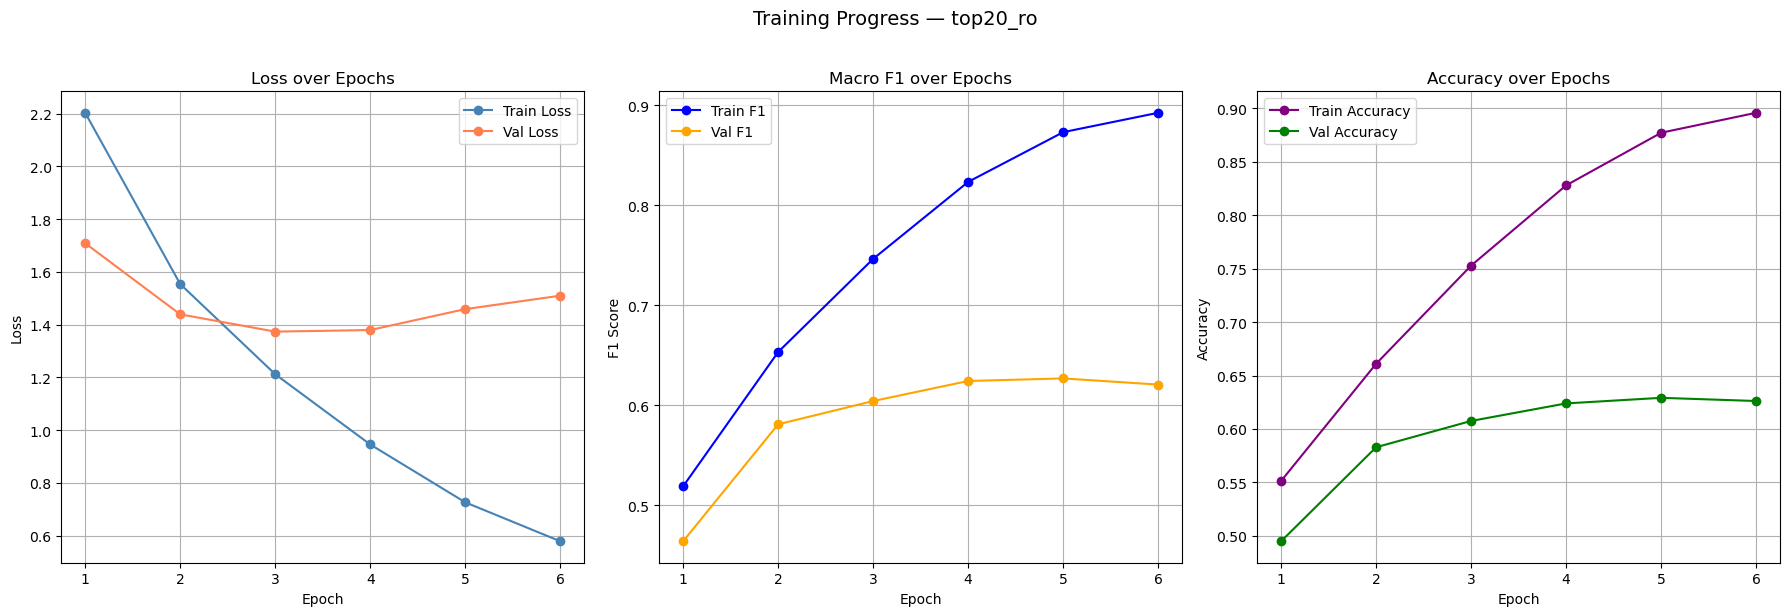

In [27]:
# grafice train
plot_training_curves(
    metrics_ro20['train_losses'], metrics_ro20['val_losses'],
    metrics_ro20['train_f1s'],   metrics_ro20['val_f1s'],
    metrics_ro20['train_accs'],  metrics_ro20['val_accs'],
    dataset_name="top20_ro"
)

In [28]:
# evaluare test
test_preds_ro20, test_f1_ro20, test_acc_ro20 = evaluate_with_voting(
    texts_test, y_test, X_test,
    tokenizer, label_encoder, device,
    dataset_name="top20_ro", model_path=best_path_ro20
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Incarcat best model din best_model_fusion_top20_ro.pt

Evaluare fusion cu majority voting — top20_ro
  0/1319
  100/1319
  200/1319
  300/1319
  400/1319
  500/1319
  600/1319
  700/1319
  800/1319
  900/1319
  1000/1319
  1100/1319
  1200/1319
  1300/1319

Test F1 macro: 0.5936 | Accuracy: 0.6073
                    precision    recall  f1-score   support

    Adrian Dumitru       0.69      0.77      0.72        77
Alexandra Andronie       0.42      0.52      0.47        46
  Alexandru Costea       0.80      0.59      0.68       100
  Alexandru Toader       0.69      0.80      0.74        30
     Alina Manaila       0.66      0.55      0.60        42
     Alina Popescu       0.49      0.38      0.42        48
   Andrada Giubega       0.89      0.78      0.83        41
    Andreea Tobias       0.64      0.55      0.59        29
    Bogdan Pacurar       0.69      0.70      0.69        96
   Daniela Chihaia       0.64      0.64      0.64        39
     Diana Nechita       0.69      0.78 

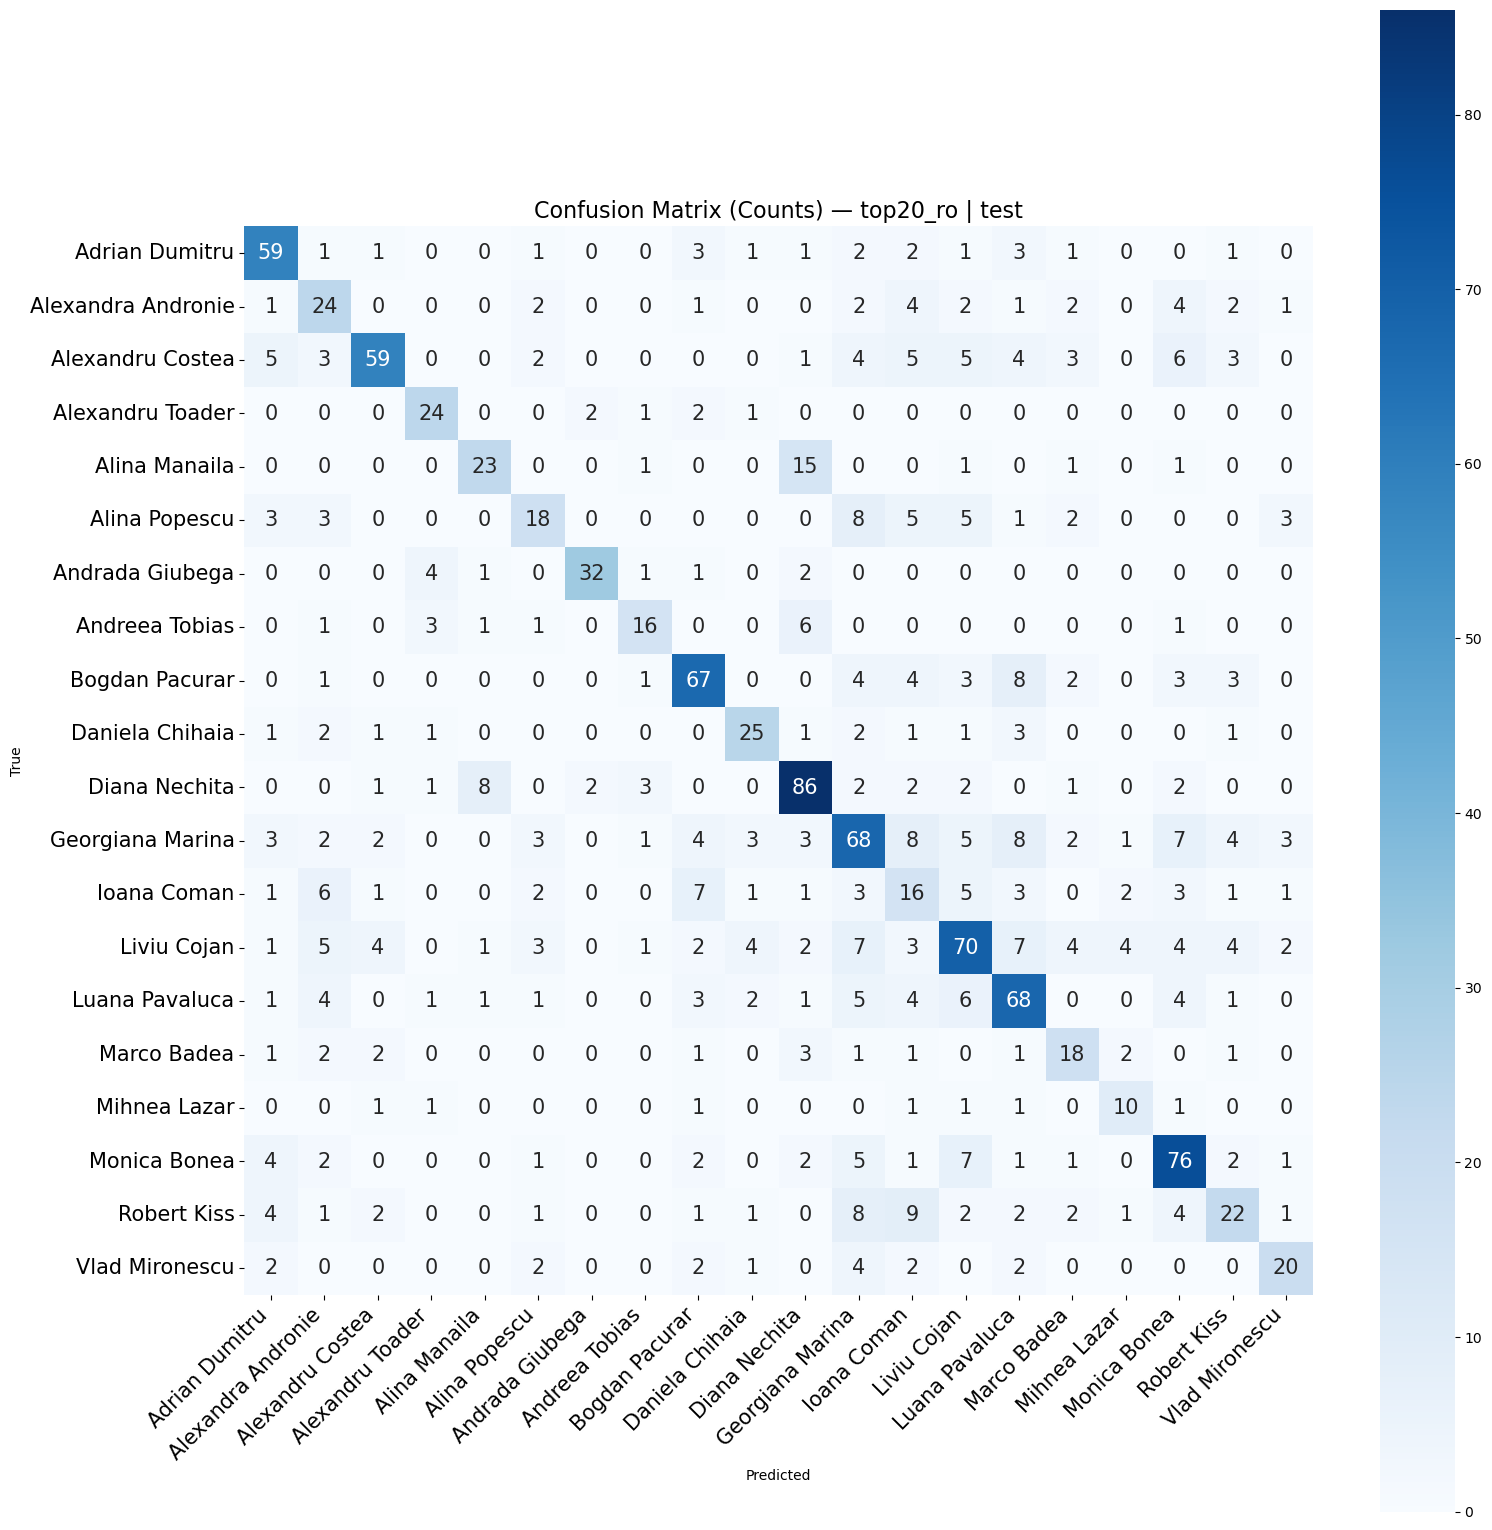

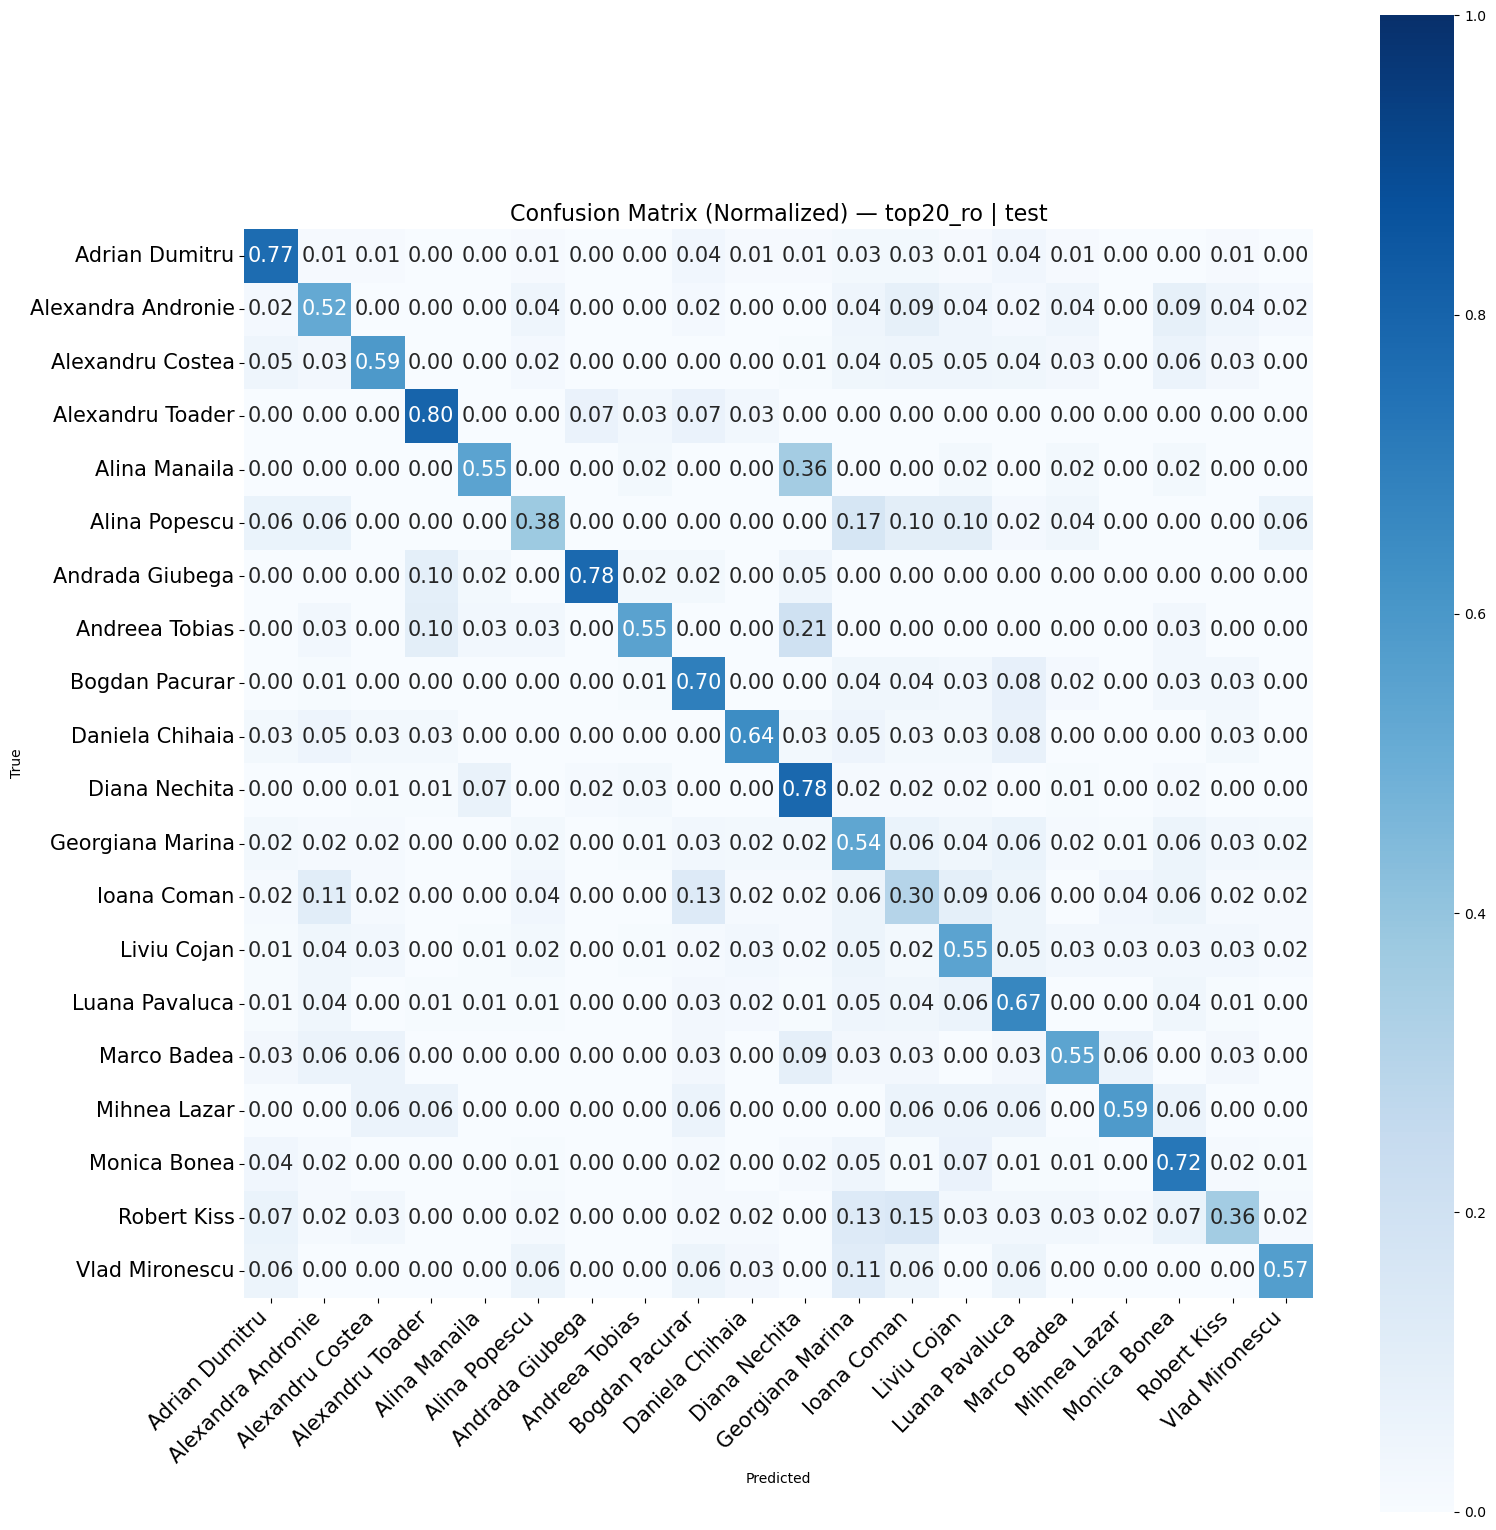

In [29]:
plot_confusion_matrix_bert_fusion(
    y_test, test_preds_ro20, label_encoder,
    dataset_name="top20_ro", split='test'
)

In [31]:
results.append({
    'Experiment':  'BERT Fusion',
    'Dataset':     'top20_ro',
    'F1 Macro':    round(test_f1_ro20, 4),
    'Accuracy':    round(test_acc_ro20, 4),
    'Best Val F1': round(metrics_ro20['best_val_f1'], 4)
})

In [32]:
print(pd.DataFrame(results))

    Experiment   Dataset  F1 Macro  Accuracy  Best Val F1
0  BERT Fusion  top20_ro    0.5936    0.6073       0.6268


#### top 40 ro

In [13]:
# citim
top40_ro_train = pd.read_csv('final_stilo/top40_ro_train.csv')
top40_ro_val = pd.read_csv('final_stilo/top40_ro_val.csv')
top40_ro_test = pd.read_csv('final_stilo/top40_ro_test.csv')

In [14]:
# loaderele
train_loader_ro40, val_loader_ro40, test_loader_ro40, label_encoder40, texts_test40, y_test40, X_test40 = build_dataloaders_fusion(
    top40_ro_train, top40_ro_val, top40_ro_test,
    tokenizer, STYLO_FEATURES, batch_size=8
)

Autori: ['Adrian Dumitru' 'Alexandra Andronie' 'Alexandru Costea'
 'Alexandru Toader' 'Alina Manaila' 'Alina Popescu' 'Ana Petrescu'
 'Anca Dumitrescu' 'Andrada Giubega' 'Andreea Neblea' 'Andreea Tobias'
 'Bogdan Pacurar' 'Carmen Zanfir' 'Catalin Costache' 'Cosmin Pirv'
 'Cristian Anton' 'Cristian Matei' 'Dan Duca' 'Daniela Chihaia'
 'Diana Nechita' 'Dorin Oancea' 'Georgel Costita' 'Georgiana Marina'
 'Ioana Coman' 'Laura Buciu' 'Leila Bolat' 'Liviu Cojan' 'Luana Pavaluca'
 'Luminita Turcu' 'Marco Badea' 'Mihai Draghici' 'Mihnea Lazar'
 'Monica Bonea' 'Otilia Serescu' 'Petru Mazilu' 'Raul Netoiu'
 'Robert Kiss' 'Tatiana Beliuta' 'Valentina Postelnicu' 'Vlad Mironescu']

[DEBUG] Combining chars BEFORE clean:
Train combining: 1
Val   combining: 2
Test  combining: 2

[DEBUG] UNK check:
Train UNK: 10
Val   UNK: 40
Test  UNK: 0

[DEBUG] Combining chars AFTER clean:
Train combining: 0
Val   combining: 0
Test  combining: 0
Autori: 40 | Stylo features: 33


In [ ]:
# run
model_ro40, best_path_ro40, metrics_ro40 = run_transformer_stilo(
    train_loader_ro40,
    val_loader_ro40,
    num_labels=len(label_encoder40.classes_),
    num_stylo_features=len(STYLO_FEATURES),
    device=device,
    dataset_name="top40_ro",
    epochs=6
)
# 506 minute

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/6
  Batch 0/8374 loss: 3.5280
  Batch 100/8374 loss: 3.8160
  Batch 200/8374 loss: 3.7248
  Batch 300/8374 loss: 3.3583
  Batch 400/8374 loss: 3.3588
  Batch 500/8374 loss: 3.5556
  Batch 600/8374 loss: 3.4688
  Batch 700/8374 loss: 3.8445
  Batch 800/8374 loss: 3.2550
  Batch 900/8374 loss: 3.3702
  Batch 1000/8374 loss: 3.6334
  Batch 1100/8374 loss: 3.4787
  Batch 1200/8374 loss: 3.3401
  Batch 1300/8374 loss: 3.4247
  Batch 1400/8374 loss: 2.7391
  Batch 1500/8374 loss: 3.1739
  Batch 1600/8374 loss: 2.8247
  Batch 1700/8374 loss: 2.8808
  Batch 1800/8374 loss: 3.2157
  Batch 1900/8374 loss: 2.6945
  Batch 2000/8374 loss: 2.5250
  Batch 2100/8374 loss: 2.7226
  Batch 2200/8374 loss: 2.7374
  Batch 2300/8374 loss: 2.4727
  Batch 2400/8374 loss: 3.2590
  Batch 2500/8374 loss: 2.8922
  Batch 2600/8374 loss: 2.8741
  Batch 2700/8374 loss: 3.1895
  Batch 2800/8374 loss: 2.8002
  Batch 2900/8374 loss: 2.8075
  Batch 3000/8374 loss: 3.0155
  Batch 3100/8374 loss: 2.7024
  Batch 3

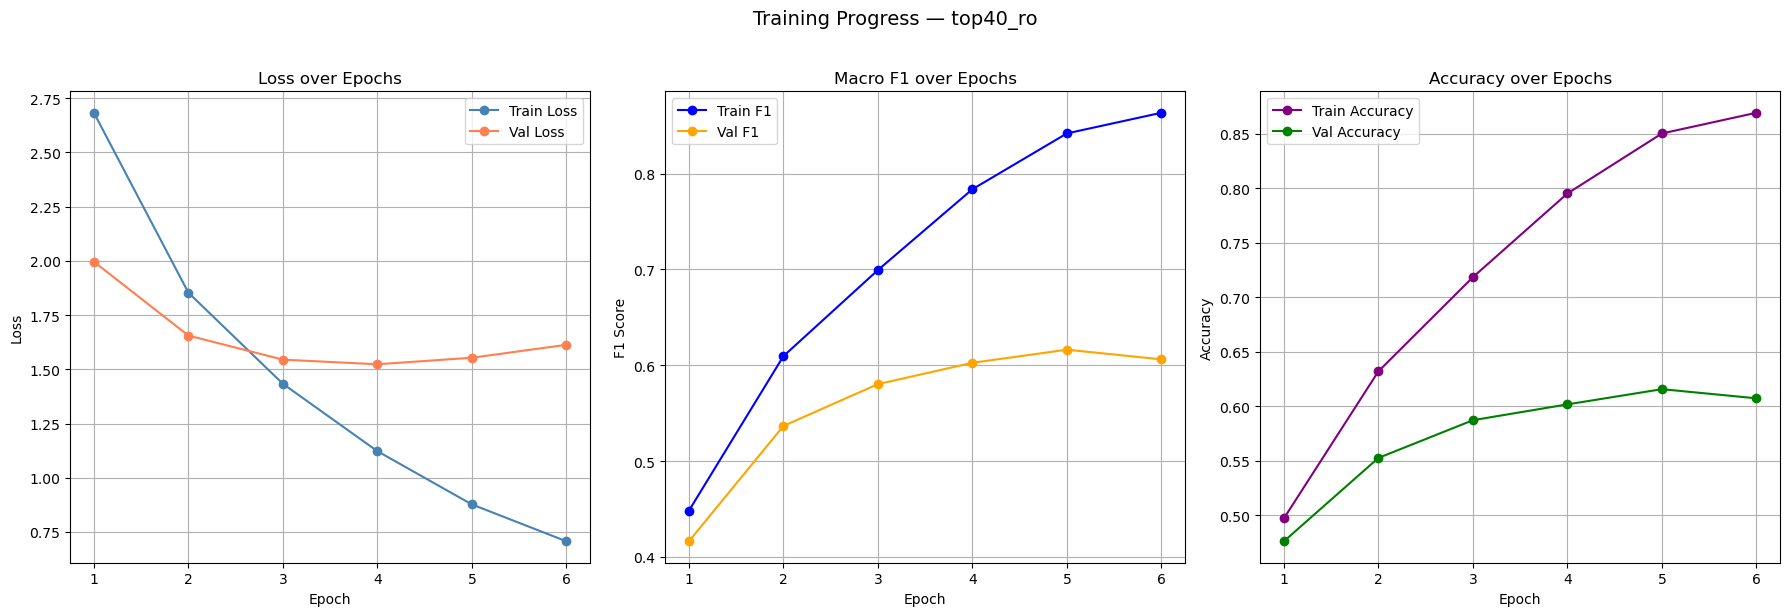

In [16]:
plot_training_curves(
    metrics_ro40['train_losses'], metrics_ro40['val_losses'],
    metrics_ro40['train_f1s'],   metrics_ro40['val_f1s'],
    metrics_ro40['train_accs'],  metrics_ro40['val_accs'],
    dataset_name="top40_ro"
)

In [17]:
print(best_path_ro40)

best_model_fusion_top40_ro.pt


In [18]:
test_preds_ro40, test_f1_ro40, test_acc_ro40 = evaluate_with_voting(
    texts_test40, y_test40, X_test40,
    tokenizer, label_encoder40, device,
    dataset_name="top40_ro", model_path=best_path_ro40
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Incarcat best model din best_model_fusion_top40_ro.pt

Evaluare fusion cu majority voting — top40_ro
  0/1761
  100/1761
  200/1761
  300/1761
  400/1761
  500/1761
  600/1761
  700/1761
  800/1761
  900/1761
  1000/1761
  1100/1761
  1200/1761
  1300/1761
  1400/1761
  1500/1761
  1600/1761
  1700/1761

Test F1 macro: 0.5795 | Accuracy: 0.5963
                      precision    recall  f1-score   support

      Adrian Dumitru       0.74      0.71      0.73        77
  Alexandra Andronie       0.38      0.54      0.45        46
    Alexandru Costea       0.75      0.61      0.67       100
    Alexandru Toader       0.65      0.67      0.66        30
       Alina Manaila       0.66      0.45      0.54        42
       Alina Popescu       0.39      0.33      0.36        48
        Ana Petrescu       0.90      0.86      0.88        22
     Anca Dumitrescu       0.88      0.82      0.85        17
     Andrada Giubega       0.86      0.78      0.82        41
      Andreea Neblea       0.76 

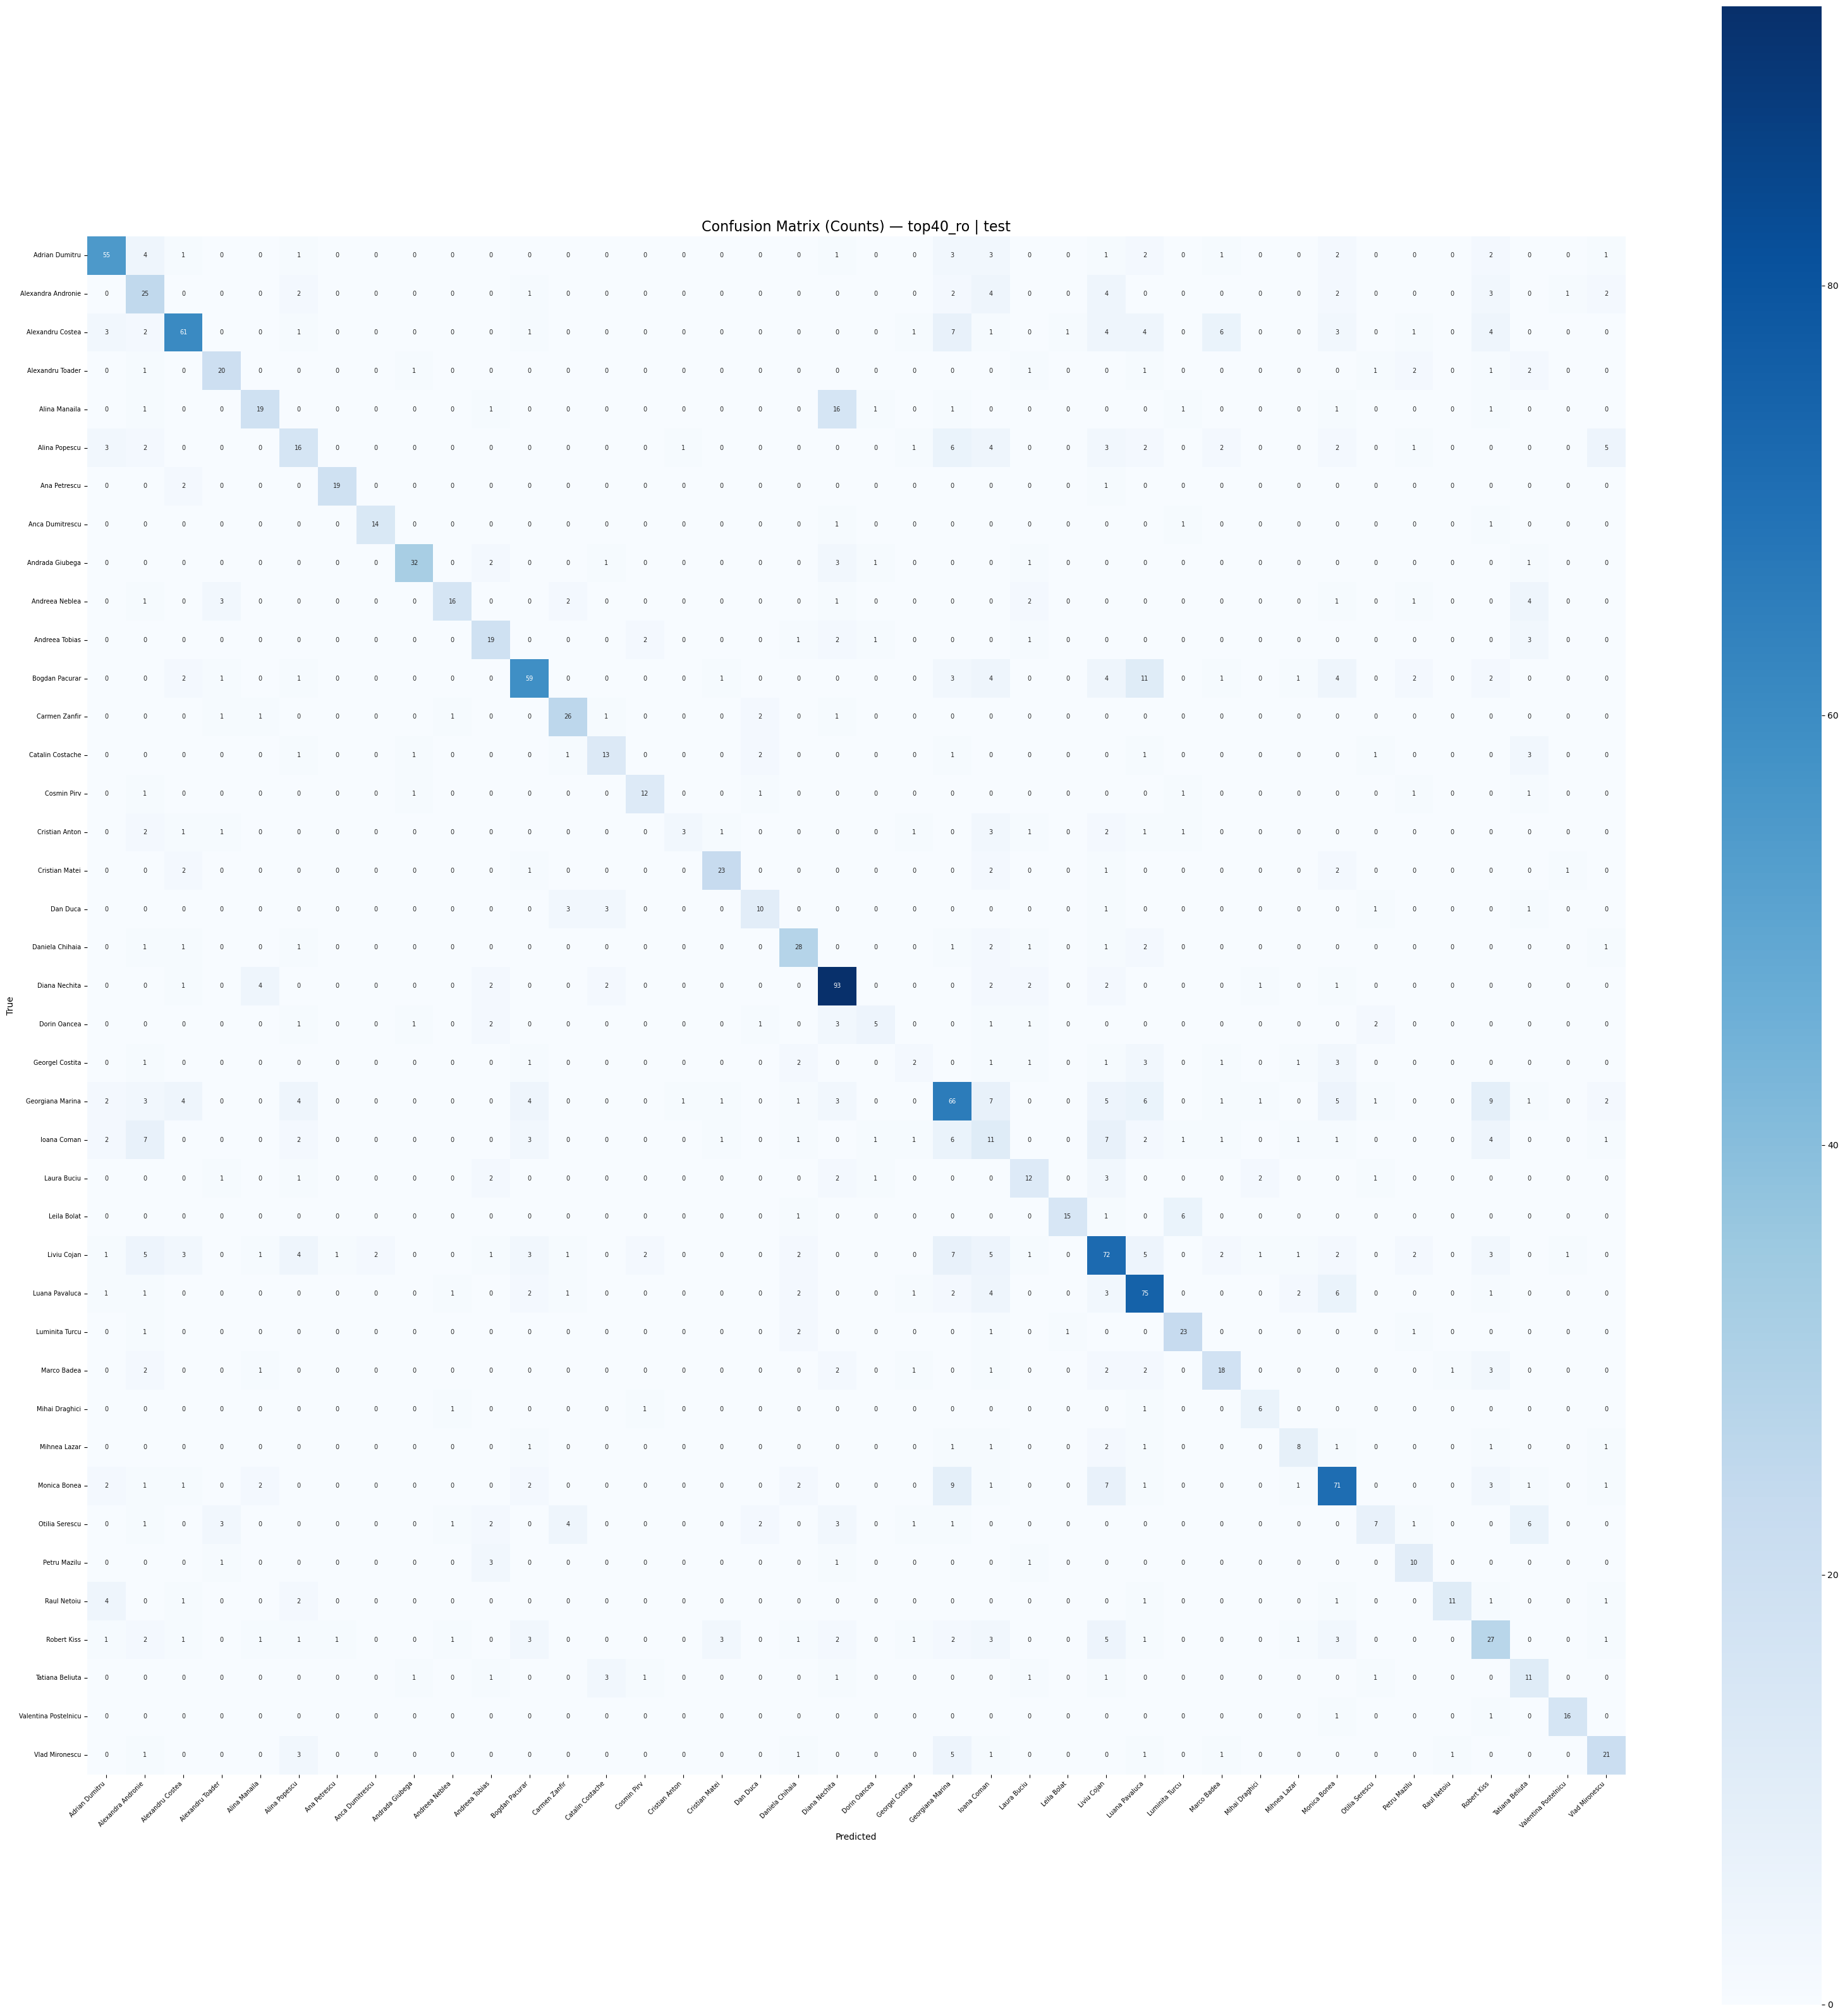

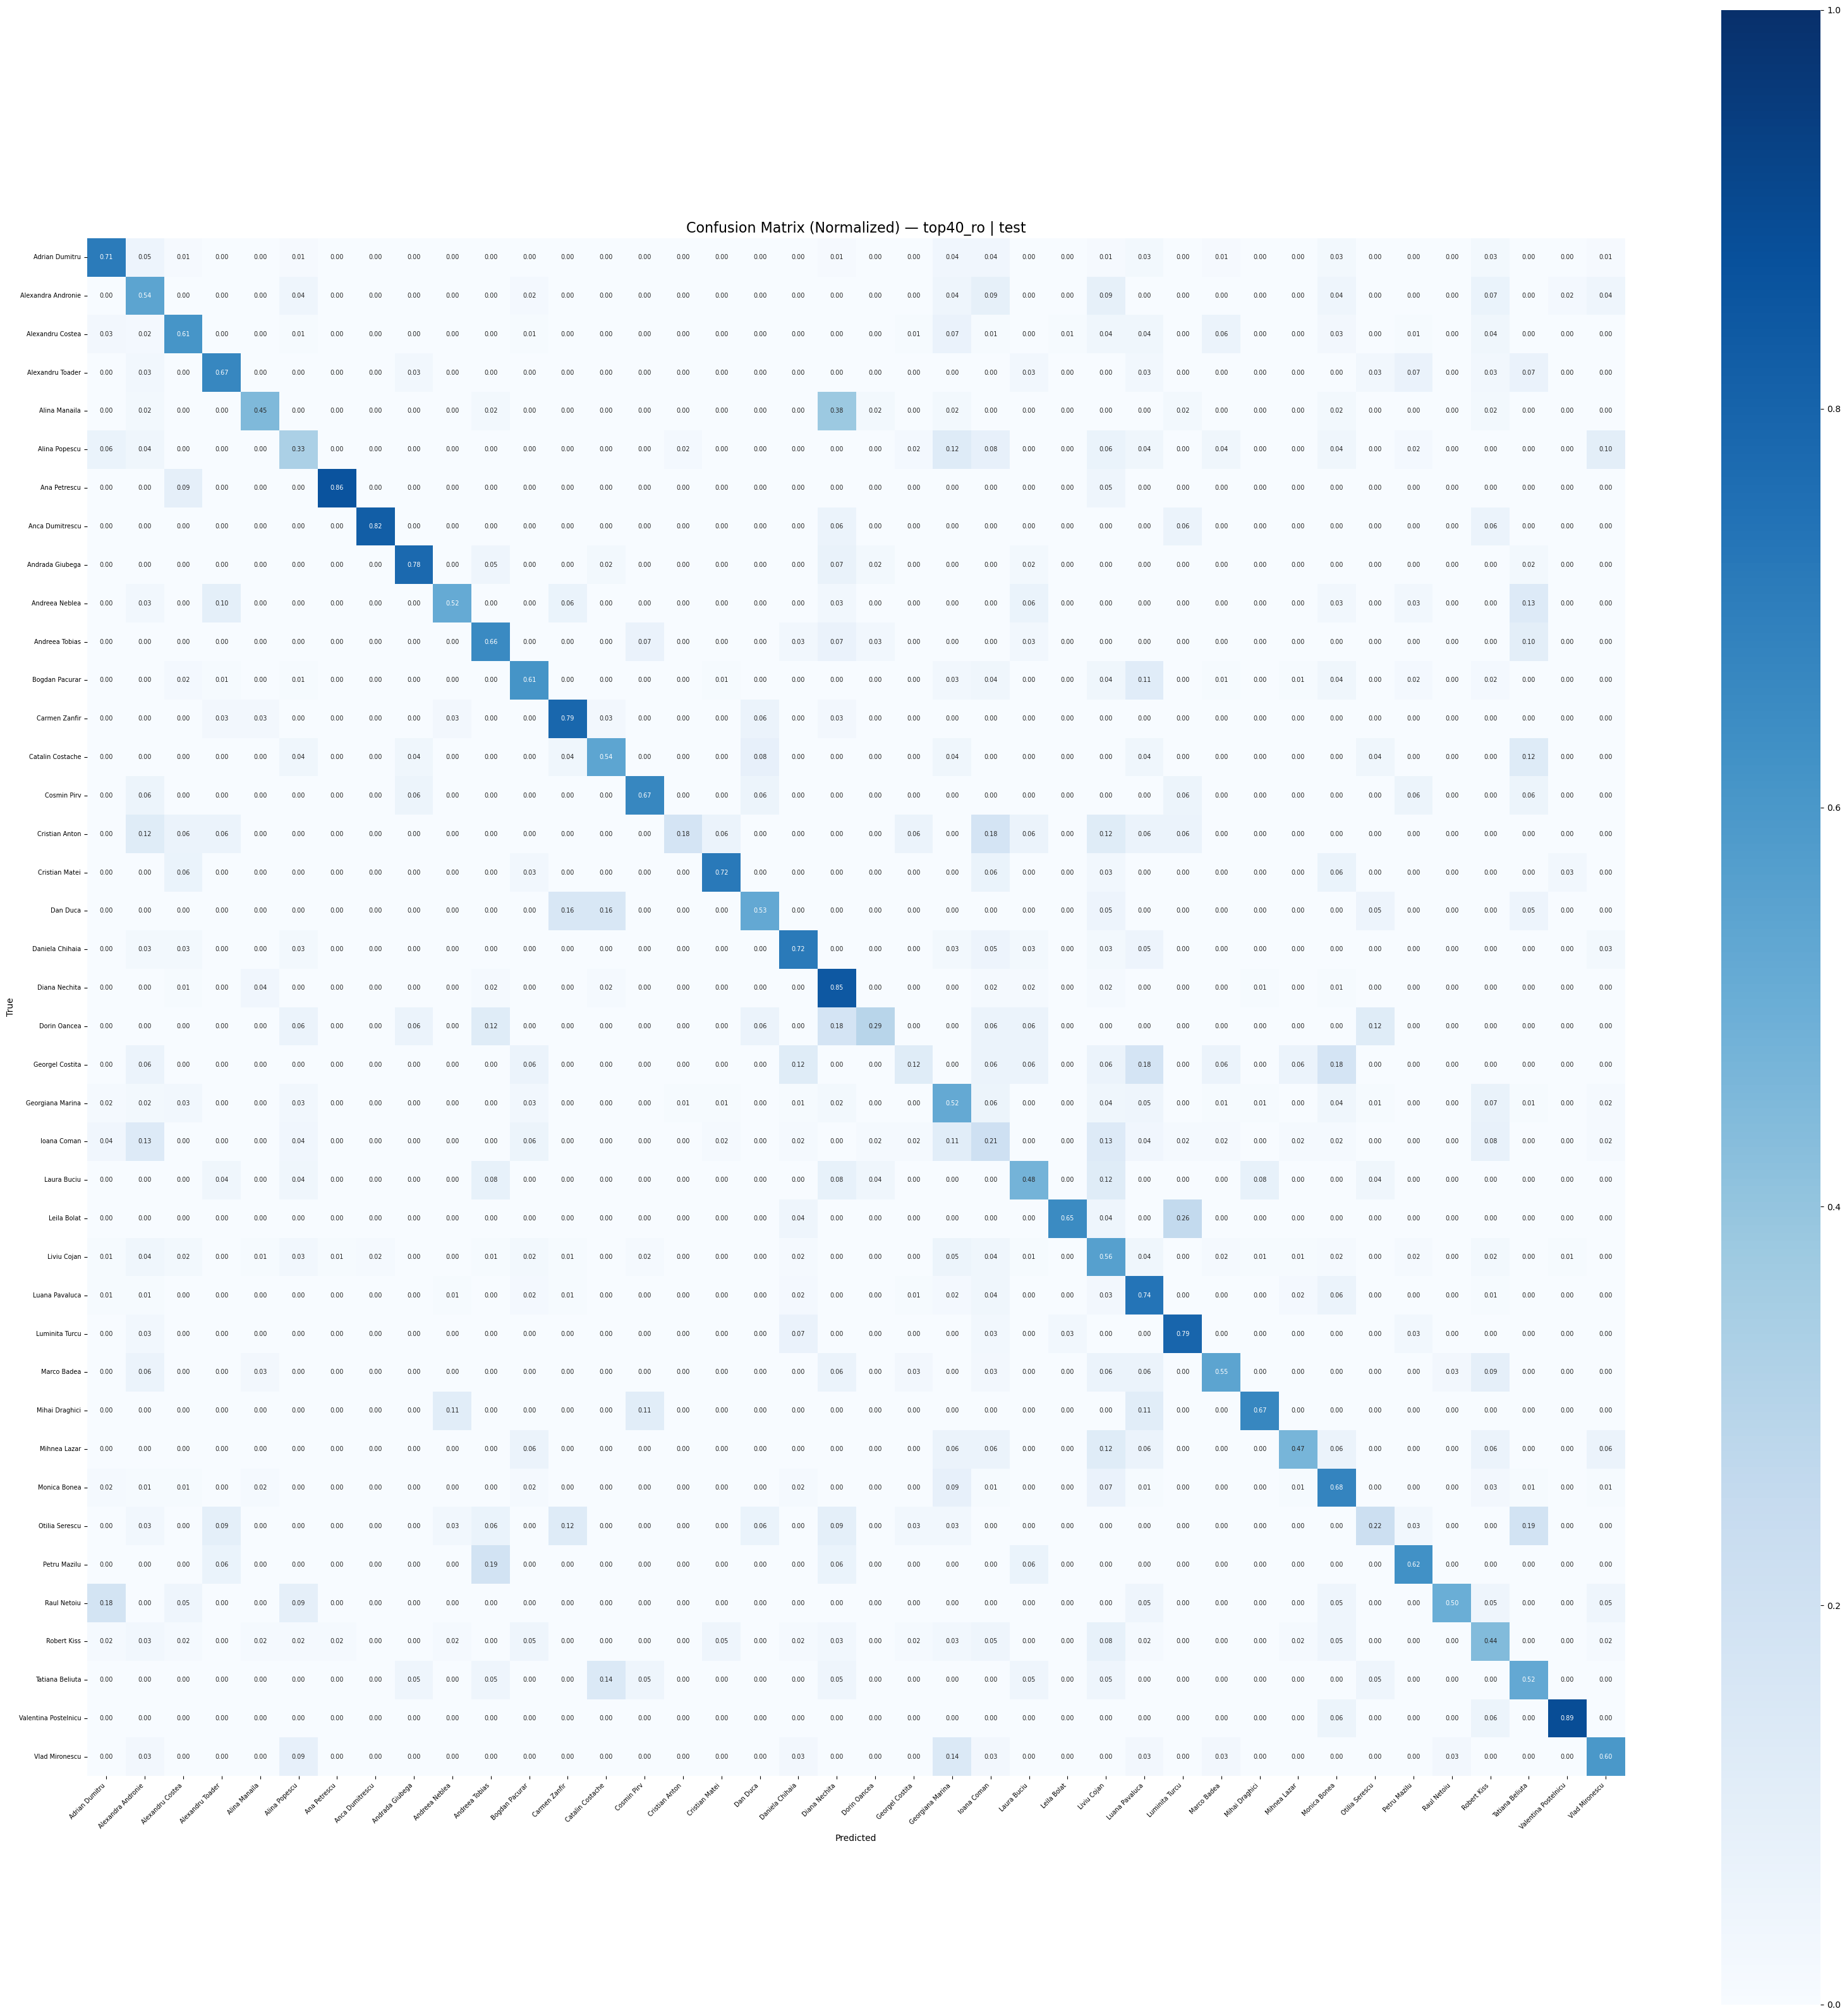

In [19]:
plot_confusion_matrix_bert_fusion(
    y_test40, test_preds_ro40, label_encoder40,
    dataset_name="top40_ro", split='test'
)

In [21]:
results.append({
    'Experiment':  'BERT Fusion',
    'Dataset':     'top40_ro',
    'F1 Macro':    round(test_f1_ro40, 4),
    'Accuracy':    round(test_acc_ro40, 4),
    'Best Val F1': round(metrics_ro40['best_val_f1'], 4)
})

In [22]:
print(pd.DataFrame(results))

    Experiment   Dataset  F1 Macro  Accuracy  Best Val F1
0  BERT Fusion  top40_ro    0.5795    0.5963       0.6162


- checkpoint : write down results file

In [ ]:
# scriem results intr-un fisier text 
import os
import json

results_folder = 'results_fusion'
os.mkdir(results_folder)
json_path = os.path.join(results_folder, 'results_fusion.json')
with open(json_path, 'w') as f:
    json.dump(results, f, indent=2)
    """
    if indent is a non-negative integer, then JSON array elements and object 
    members will be pretty-printed with that indent level. 
    An indent level of 0 will only insert newlines. 
    None is the most compact representation
    """


### Moldova
#### top 20

In [15]:
# citim
top20_mo_train = pd.read_csv('final_stilo/top20_mo_train.csv')
top20_mo_val = pd.read_csv('final_stilo/top20_mo_val.csv')
top20_mo_test = pd.read_csv('final_stilo/top20_mo_test.csv')

In [16]:
# loaderele
train_loader_mo20, val_loader_mo20, test_loader_mo20, label_encoder20, texts_test20, y_test20, X_test20 = build_dataloaders_fusion(
    top20_mo_train, top20_mo_val, top20_mo_test,
    tokenizer, STYLO_FEATURES, batch_size=8
)

Autori: ['Aliona Ciurca' 'Ana-Maria Dolghii' 'Cristian Sava' 'Cristina Dulea'
 'Cristina Mirca' 'Cristina Popescu' 'Diana Gatcan' 'Diana Severin'
 'Ecaterina Arvintii' 'Malvina Cojocari' 'Marina Ciobanu' 'Maxim Stratan'
 'Mihaela Conovali' 'Milena Onisim' 'Nicoleta Braghis' 'Stela Untila'
 'Svetlana Cartin' 'Svetlana Cojocaru' 'Valentina Buza' 'Viorica Rusu']

[DEBUG] Combining chars BEFORE clean:
Train combining: 343
Val   combining: 422
Test  combining: 366

[DEBUG] UNK check:
Train UNK: 43
Val   UNK: 33
Test  UNK: 53

[DEBUG] Combining chars AFTER clean:
Train combining: 0
Val   combining: 0
Test  combining: 0
Autori: 20 | Stylo features: 33


In [ ]:
# asta o rulezi!!!
# void (*(*f[]) () ) ()
model_mo20, best_path_mo20, metrics_mo20 = run_transformer_stilo(
    train_loader_mo20,
    val_loader_mo20,
    num_labels=len(label_encoder20.classes_),
    num_stylo_features=len(STYLO_FEATURES),
    device=device,
    dataset_name="top20_mo",
    epochs=6
)
# 313 minute

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/6
  Batch 0/4917 loss: 3.0833
  Batch 100/4917 loss: 2.9477
  Batch 200/4917 loss: 2.9442
  Batch 300/4917 loss: 2.9427
  Batch 400/4917 loss: 3.0978
  Batch 500/4917 loss: 2.6662
  Batch 600/4917 loss: 2.4988
  Batch 700/4917 loss: 2.3822
  Batch 800/4917 loss: 2.2451
  Batch 900/4917 loss: 2.2375
  Batch 1000/4917 loss: 1.9673
  Batch 1100/4917 loss: 2.2350
  Batch 1200/4917 loss: 2.1634
  Batch 1300/4917 loss: 2.4081
  Batch 1400/4917 loss: 2.6519
  Batch 1500/4917 loss: 2.0267
  Batch 1600/4917 loss: 1.8708
  Batch 1700/4917 loss: 1.5754
  Batch 1800/4917 loss: 1.6933
  Batch 1900/4917 loss: 2.2291
  Batch 2000/4917 loss: 2.4008
  Batch 2100/4917 loss: 2.3691
  Batch 2200/4917 loss: 1.8462
  Batch 2300/4917 loss: 1.4779
  Batch 2400/4917 loss: 2.3874
  Batch 2500/4917 loss: 1.9487
  Batch 2600/4917 loss: 1.9979
  Batch 2700/4917 loss: 2.0813
  Batch 2800/4917 loss: 1.3895
  Batch 2900/4917 loss: 1.1436
  Batch 3000/4917 loss: 1.3831
  Batch 3100/4917 loss: 1.8264
  Batch 3

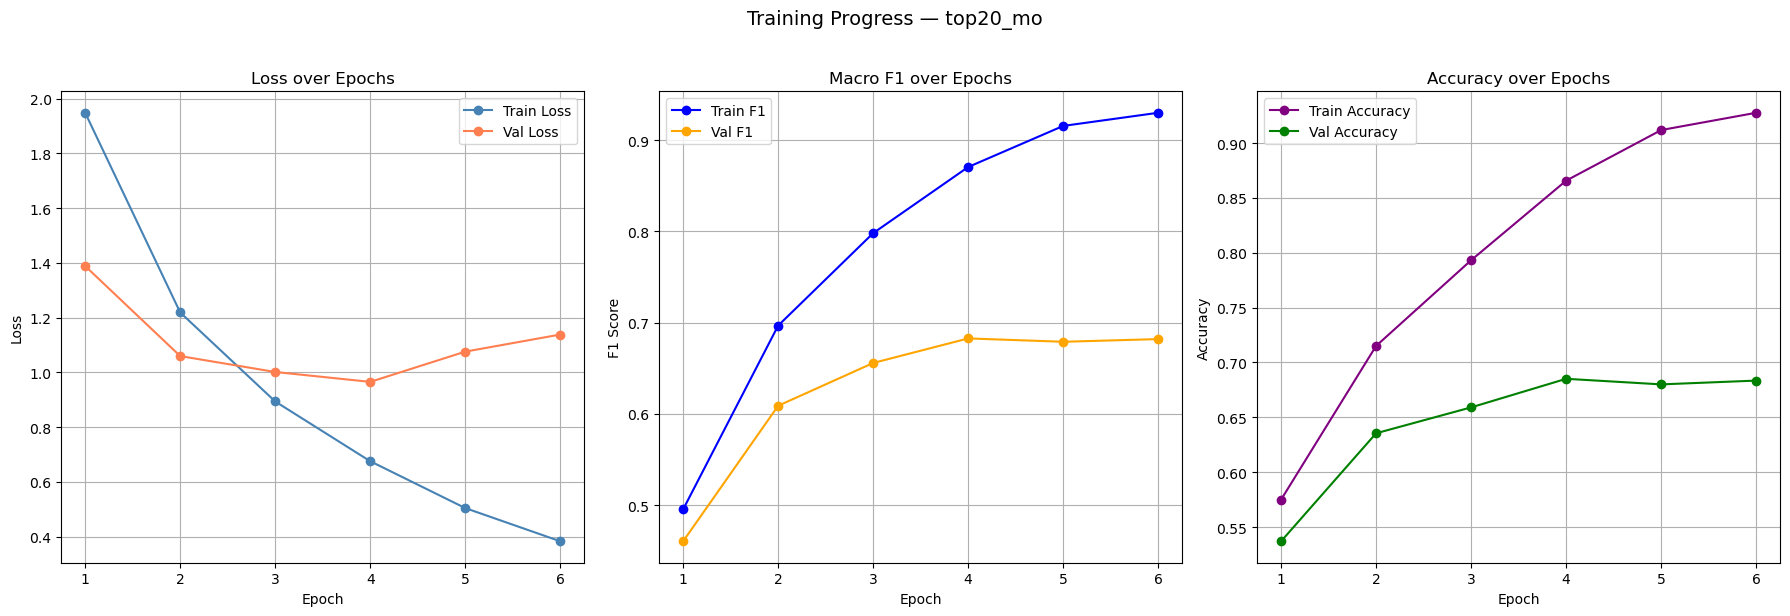

In [18]:
plot_training_curves(
    metrics_mo20['train_losses'], metrics_mo20['val_losses'],
    metrics_mo20['train_f1s'],   metrics_mo20['val_f1s'],
    metrics_mo20['train_accs'],  metrics_mo20['val_accs'],
    dataset_name="top20_mo"
)

In [19]:
# evaluate
test_preds_mo20, test_f1_mo20, test_acc_mo20 = evaluate_with_voting(
    texts_test20, y_test20, X_test20,
    tokenizer, label_encoder20, device,
    dataset_name="top20_mo", model_path=best_path_mo20
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Incarcat best model din best_model_fusion_top20_mo.pt

Evaluare fusion cu majority voting — top20_mo
  0/4917
  100/4917
  200/4917
  300/4917
  400/4917
  500/4917
  600/4917
  700/4917
  800/4917
  900/4917
  1000/4917
  1100/4917
  1200/4917
  1300/4917
  1400/4917
  1500/4917
  1600/4917
  1700/4917
  1800/4917
  1900/4917
  2000/4917
  2100/4917
  2200/4917
  2300/4917
  2400/4917
  2500/4917
  2600/4917
  2700/4917
  2800/4917
  2900/4917
  3000/4917
  3100/4917
  3200/4917
  3300/4917
  3400/4917
  3500/4917
  3600/4917
  3700/4917
  3800/4917
  3900/4917
  4000/4917
  4100/4917
  4200/4917
  4300/4917
  4400/4917
  4500/4917
  4600/4917
  4700/4917
  4800/4917
  4900/4917

Test F1 macro: 0.6639 | Accuracy: 0.6677
                    precision    recall  f1-score   support

     Aliona Ciurca       0.78      0.65      0.71       150
 Ana-Maria Dolghii       0.54      0.52      0.53       121
     Cristian Sava       0.52      0.49      0.51       328
    Cristina Dulea       0.5

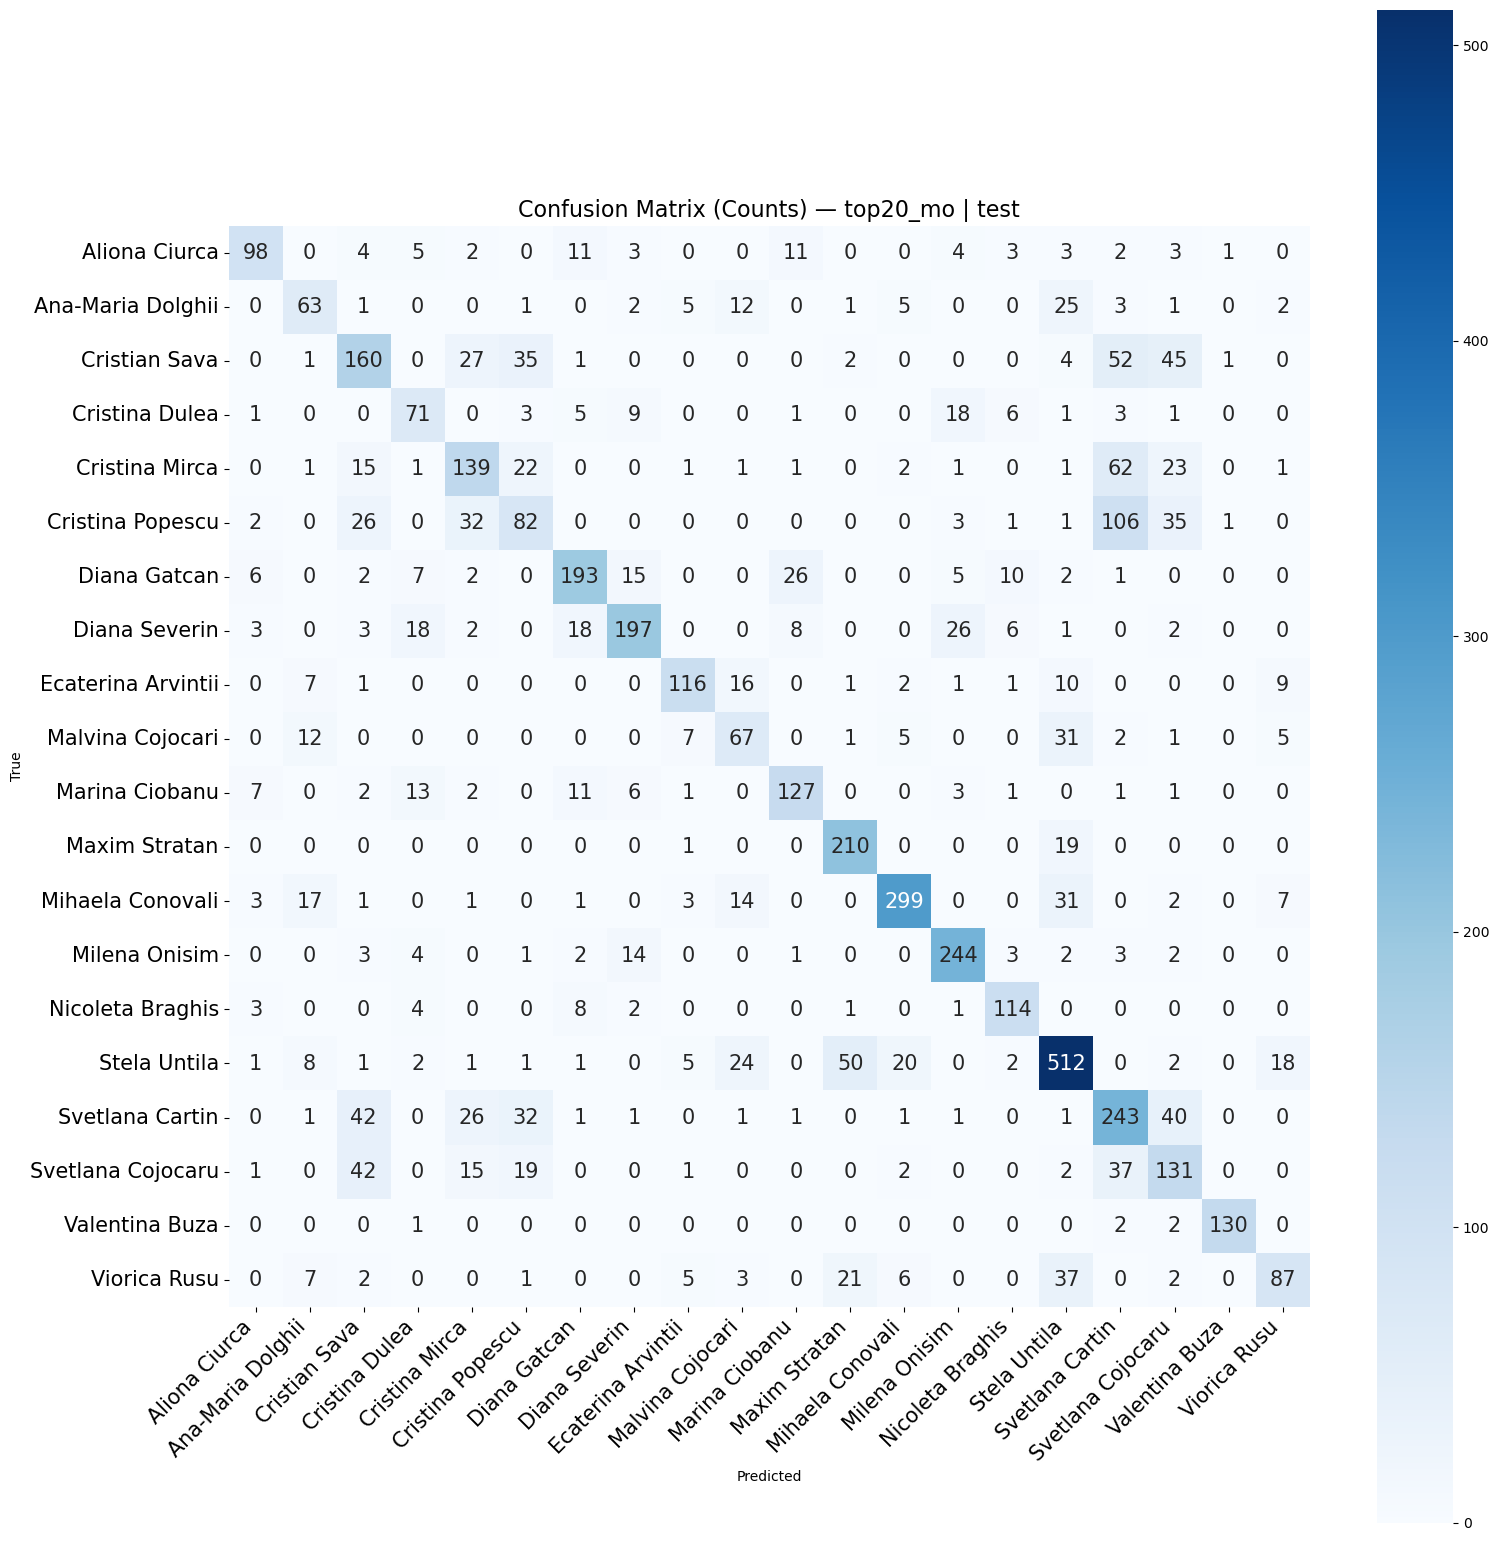

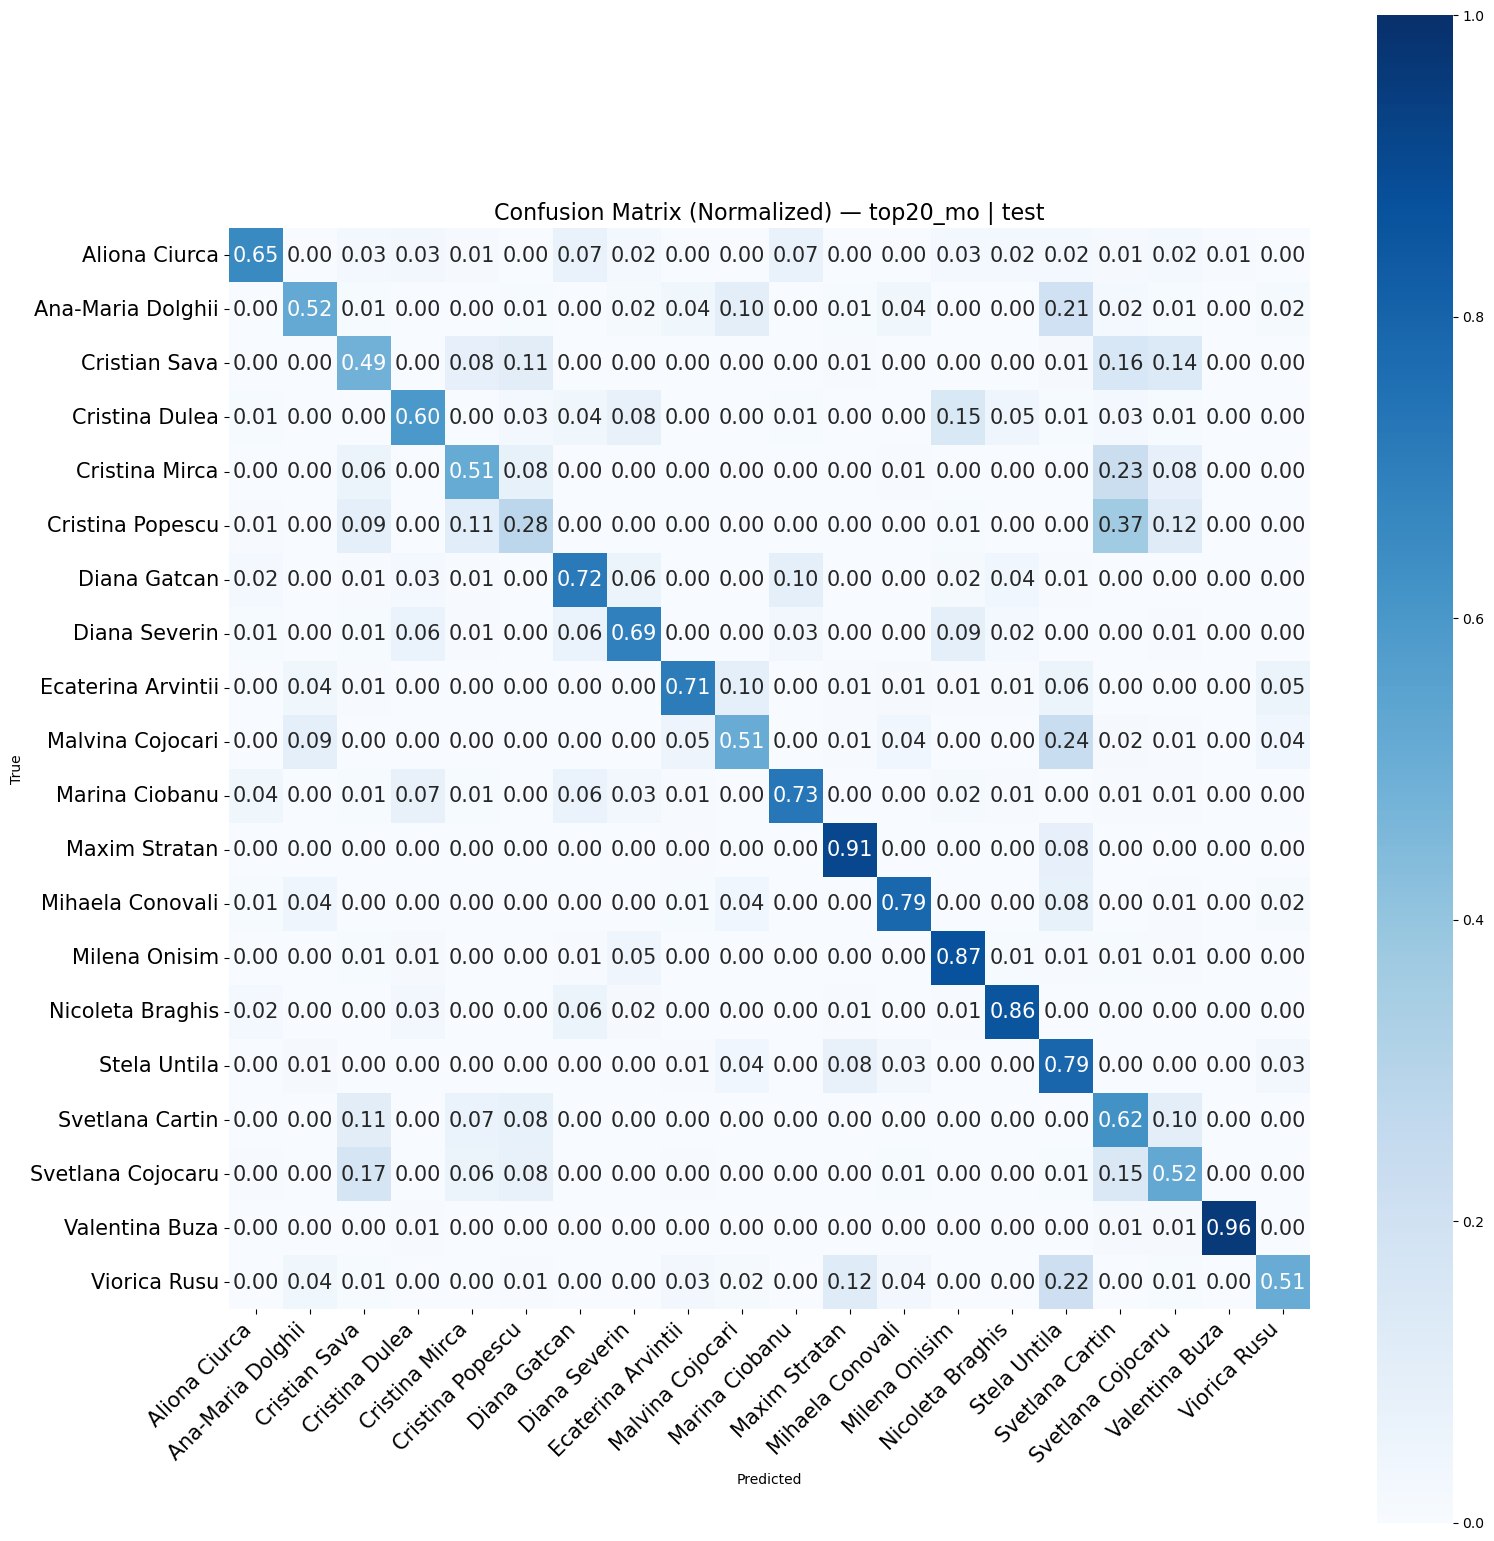

In [20]:
# confusion
plot_confusion_matrix_bert_fusion(
    y_test20, test_preds_mo20, label_encoder20,
    dataset_name="top20_mo", split='test'
)

In [21]:
results

[]

In [22]:
results.append({
    'Experiment':  'BERT Fusion',
    'Dataset':     'top20_mo',
    'F1 Macro':    round(test_f1_mo20, 4),
    'Accuracy':    round(test_acc_mo20, 4),
    'Best Val F1': round(metrics_mo20['best_val_f1'], 4)
})

In [23]:
display(pd.DataFrame(results))

,Experiment,Dataset,F1 Macro,Accuracy,Best Val F1
0,BERT Fusion,top20_mo,0.6639,0.6677,0.6827


In [ ]:
#results.pop(2)
with open(json_path, 'w') as f:
    json.dump(results, f, indent=2)


#### top 40 moldova

In [24]:
# citim
top40_mo_train = pd.read_csv('final_stilo/top40_mo_train.csv')
top40_mo_val = pd.read_csv('final_stilo/top40_mo_val.csv')
top40_mo_test = pd.read_csv('final_stilo/top40_mo_test.csv')

In [25]:
# loadere
train_loader_mo40, val_loader_mo40, test_loader_mo40, label_encoder40, texts_test40, y_test40, X_test40 = build_dataloaders_fusion(
    top40_mo_train, top40_mo_val, top40_mo_test,
    tokenizer, STYLO_FEATURES, batch_size=8
)

Autori: ['Alina Radu' 'Aliona Ciurca' 'Ana-Maria Dolghii' 'Anatolie Esanu'
 'Aneta Grosu' 'Buzdugan Loredana' 'Constantin Uzdris' 'Cristian Sava'
 'Cristina Dulea' 'Cristina Mirca' 'Cristina Popescu' 'Diana Gatcan'
 'Diana Severin' 'Dorina Butnaras' 'Ecaterina Arvintii' 'Elena Cornea'
 'Elena Mudrii' 'Elena Putregai' 'Frunza Alina' 'Malvina Cojocari'
 'Maria Palade' 'Maria Svet' 'Marina Ciobanu' 'Maxim Stratan'
 'Mihaela Conovali' 'Milena Onisim' 'Nicoleta Braghis' 'Stela Untila'
 'Svetlana Cartin' 'Svetlana Cojocaru' 'Tatiana Beghiu' 'Tatiana Rusnac'
 'Ursu Ana' 'Vadim Sterbate' 'Valentina Buza' 'Victor Cobasneanu'
 'Victor Mosneag' 'Victoria Borodin' 'Victoria Laur' 'Viorica Rusu']

[DEBUG] Combining chars BEFORE clean:
Train combining: 327
Val   combining: 351
Test  combining: 333

[DEBUG] UNK check:
Train UNK: 21
Val   UNK: 77
Test  UNK: 27

[DEBUG] Combining chars AFTER clean:
Train combining: 0
Val   combining: 0
Test  combining: 0
Autori: 40 | Stylo features: 33


In [ ]:
# RULEAZA DOAR CELULA ASTA NU SI CEA DE JOS !!!!!1
model_mo40, best_path_mo40, metrics_mo40 = run_transformer_stilo(
    train_loader_mo40,
    val_loader_mo40,
    num_labels=len(label_encoder40.classes_),
    num_stylo_features=len(STYLO_FEATURES),
    device=device,
    dataset_name="top40_mo",
    epochs=6
)
# 379 minute

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/6
  Batch 0/5902 loss: 3.6605
  Batch 100/5902 loss: 3.4463
  Batch 200/5902 loss: 3.3074
  Batch 300/5902 loss: 3.5368
  Batch 400/5902 loss: 3.1124
  Batch 500/5902 loss: 3.0660
  Batch 600/5902 loss: 3.4396
  Batch 700/5902 loss: 3.3443
  Batch 800/5902 loss: 3.0143
  Batch 900/5902 loss: 3.2866
  Batch 1000/5902 loss: 3.2118
  Batch 1100/5902 loss: 3.3685
  Batch 1200/5902 loss: 3.0257
  Batch 1300/5902 loss: 2.8970
  Batch 1400/5902 loss: 2.4544
  Batch 1500/5902 loss: 2.3655
  Batch 1600/5902 loss: 3.7302
  Batch 1700/5902 loss: 2.5947
  Batch 1800/5902 loss: 2.6483
  Batch 1900/5902 loss: 2.1101
  Batch 2000/5902 loss: 2.5387
  Batch 2100/5902 loss: 2.3684
  Batch 2200/5902 loss: 2.9364
  Batch 2300/5902 loss: 2.1196
  Batch 2400/5902 loss: 2.5271
  Batch 2500/5902 loss: 2.3464
  Batch 2600/5902 loss: 2.4029
  Batch 2700/5902 loss: 2.9769
  Batch 2800/5902 loss: 2.5024
  Batch 2900/5902 loss: 2.4980
  Batch 3000/5902 loss: 3.0194
  Batch 3100/5902 loss: 2.2980
  Batch 3

In [ ]:
# NU RULA
model_mo40, best_path_mo40, metrics_mo40 = run_transformer_stilo(
    train_loader_mo40,
    val_loader_mo40,
    num_labels=len(label_encoder40.classes_),
    num_stylo_features=len(STYLO_FEATURES),
    device=device,
    dataset_name="top40_mo",
    epochs=6
)
# 363 minute


Epoch 1/6
  Batch 0/5902 loss: 3.6330
  Batch 100/5902 loss: 3.6364
  Batch 200/5902 loss: 3.5834
  Batch 300/5902 loss: 3.6425
  Batch 400/5902 loss: 3.4442
  Batch 500/5902 loss: 3.3230
  Batch 600/5902 loss: 3.4614
  Batch 700/5902 loss: 3.5401
  Batch 800/5902 loss: 3.1587
  Batch 900/5902 loss: 3.1205
  Batch 1000/5902 loss: 3.1605
  Batch 1100/5902 loss: 2.7971
  Batch 1200/5902 loss: 3.1116
  Batch 1300/5902 loss: 2.8129
  Batch 1400/5902 loss: 2.3272
  Batch 1500/5902 loss: 2.6715
  Batch 1600/5902 loss: 3.6974
  Batch 1700/5902 loss: 2.9182
  Batch 1800/5902 loss: 2.3296
  Batch 1900/5902 loss: 1.9415
  Batch 2000/5902 loss: 2.1389
  Batch 2100/5902 loss: 2.2220
  Batch 2200/5902 loss: 2.6574
  Batch 2300/5902 loss: 1.5911
  Batch 2400/5902 loss: 2.5344
  Batch 2500/5902 loss: 2.6170
  Batch 2600/5902 loss: 2.2976
  Batch 2700/5902 loss: 3.2328
  Batch 2800/5902 loss: 2.3584
  Batch 2900/5902 loss: 2.3038
  Batch 3000/5902 loss: 2.8888
  Batch 3100/5902 loss: 2.2444
  Batch 3

/tmp/ipykernel_5212/2946694791.py:50: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path, map_location=device))



Best Val F1: 0.5367


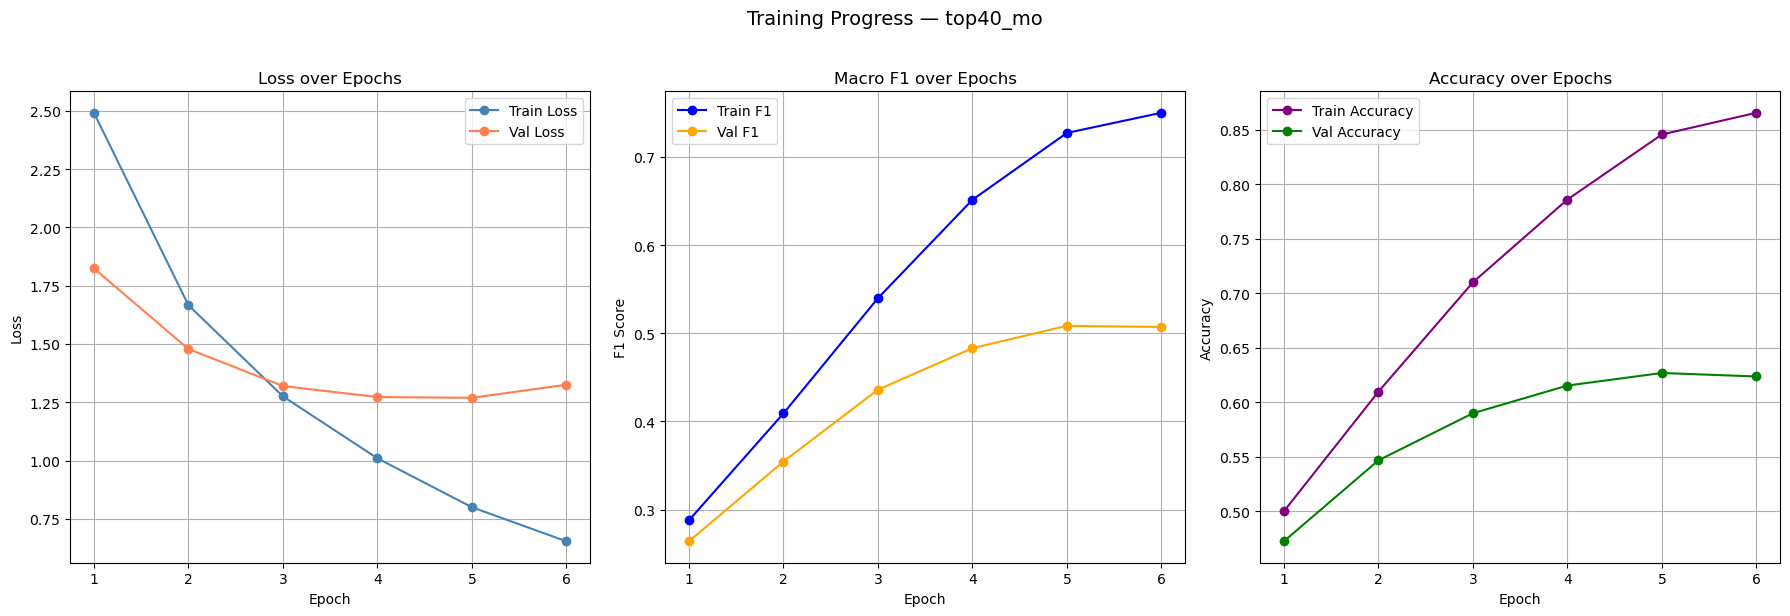

In [27]:
plot_training_curves(
    metrics_mo40['train_losses'], metrics_mo40['val_losses'],
    metrics_mo40['train_f1s'],   metrics_mo40['val_f1s'],
    metrics_mo40['train_accs'],  metrics_mo40['val_accs'],
    dataset_name="top40_mo"
)

In [29]:
# test
test_preds_mo40, test_f1_mo40, test_acc_mo40 = evaluate_with_voting(
    texts_test40, y_test40, X_test40,
    tokenizer, label_encoder40, device,
    dataset_name="top40_mo", model_path=best_path_mo40
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Incarcat best model din best_model_fusion_top40_mo.pt

Evaluare fusion cu majority voting — top40_mo
  0/5902
  100/5902
  200/5902
  300/5902
  400/5902
  500/5902
  600/5902
  700/5902
  800/5902
  900/5902
  1000/5902
  1100/5902
  1200/5902
  1300/5902
  1400/5902
  1500/5902
  1600/5902
  1700/5902
  1800/5902
  1900/5902
  2000/5902
  2100/5902
  2200/5902
  2300/5902
  2400/5902
  2500/5902
  2600/5902
  2700/5902
  2800/5902
  2900/5902
  3000/5902
  3100/5902
  3200/5902
  3300/5902
  3400/5902
  3500/5902
  3600/5902
  3700/5902
  3800/5902
  3900/5902
  4000/5902
  4100/5902
  4200/5902
  4300/5902
  4400/5902
  4500/5902
  4600/5902
  4700/5902
  4800/5902
  4900/5902
  5000/5902
  5100/5902
  5200/5902
  5300/5902
  5400/5902
  5500/5902
  5600/5902
  5700/5902
  5800/5902
  5900/5902

Test F1 macro: 0.5160 | Accuracy: 0.6347
                    precision    recall  f1-score   support

        Alina Radu       0.00      0.00      0.00        11
     Aliona Ciurca       0.7

/home/daria/miniconda3/envs/ia-labs-env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/daria/miniconda3/envs/ia-labs-env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/daria/miniconda3/envs/ia-labs-env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

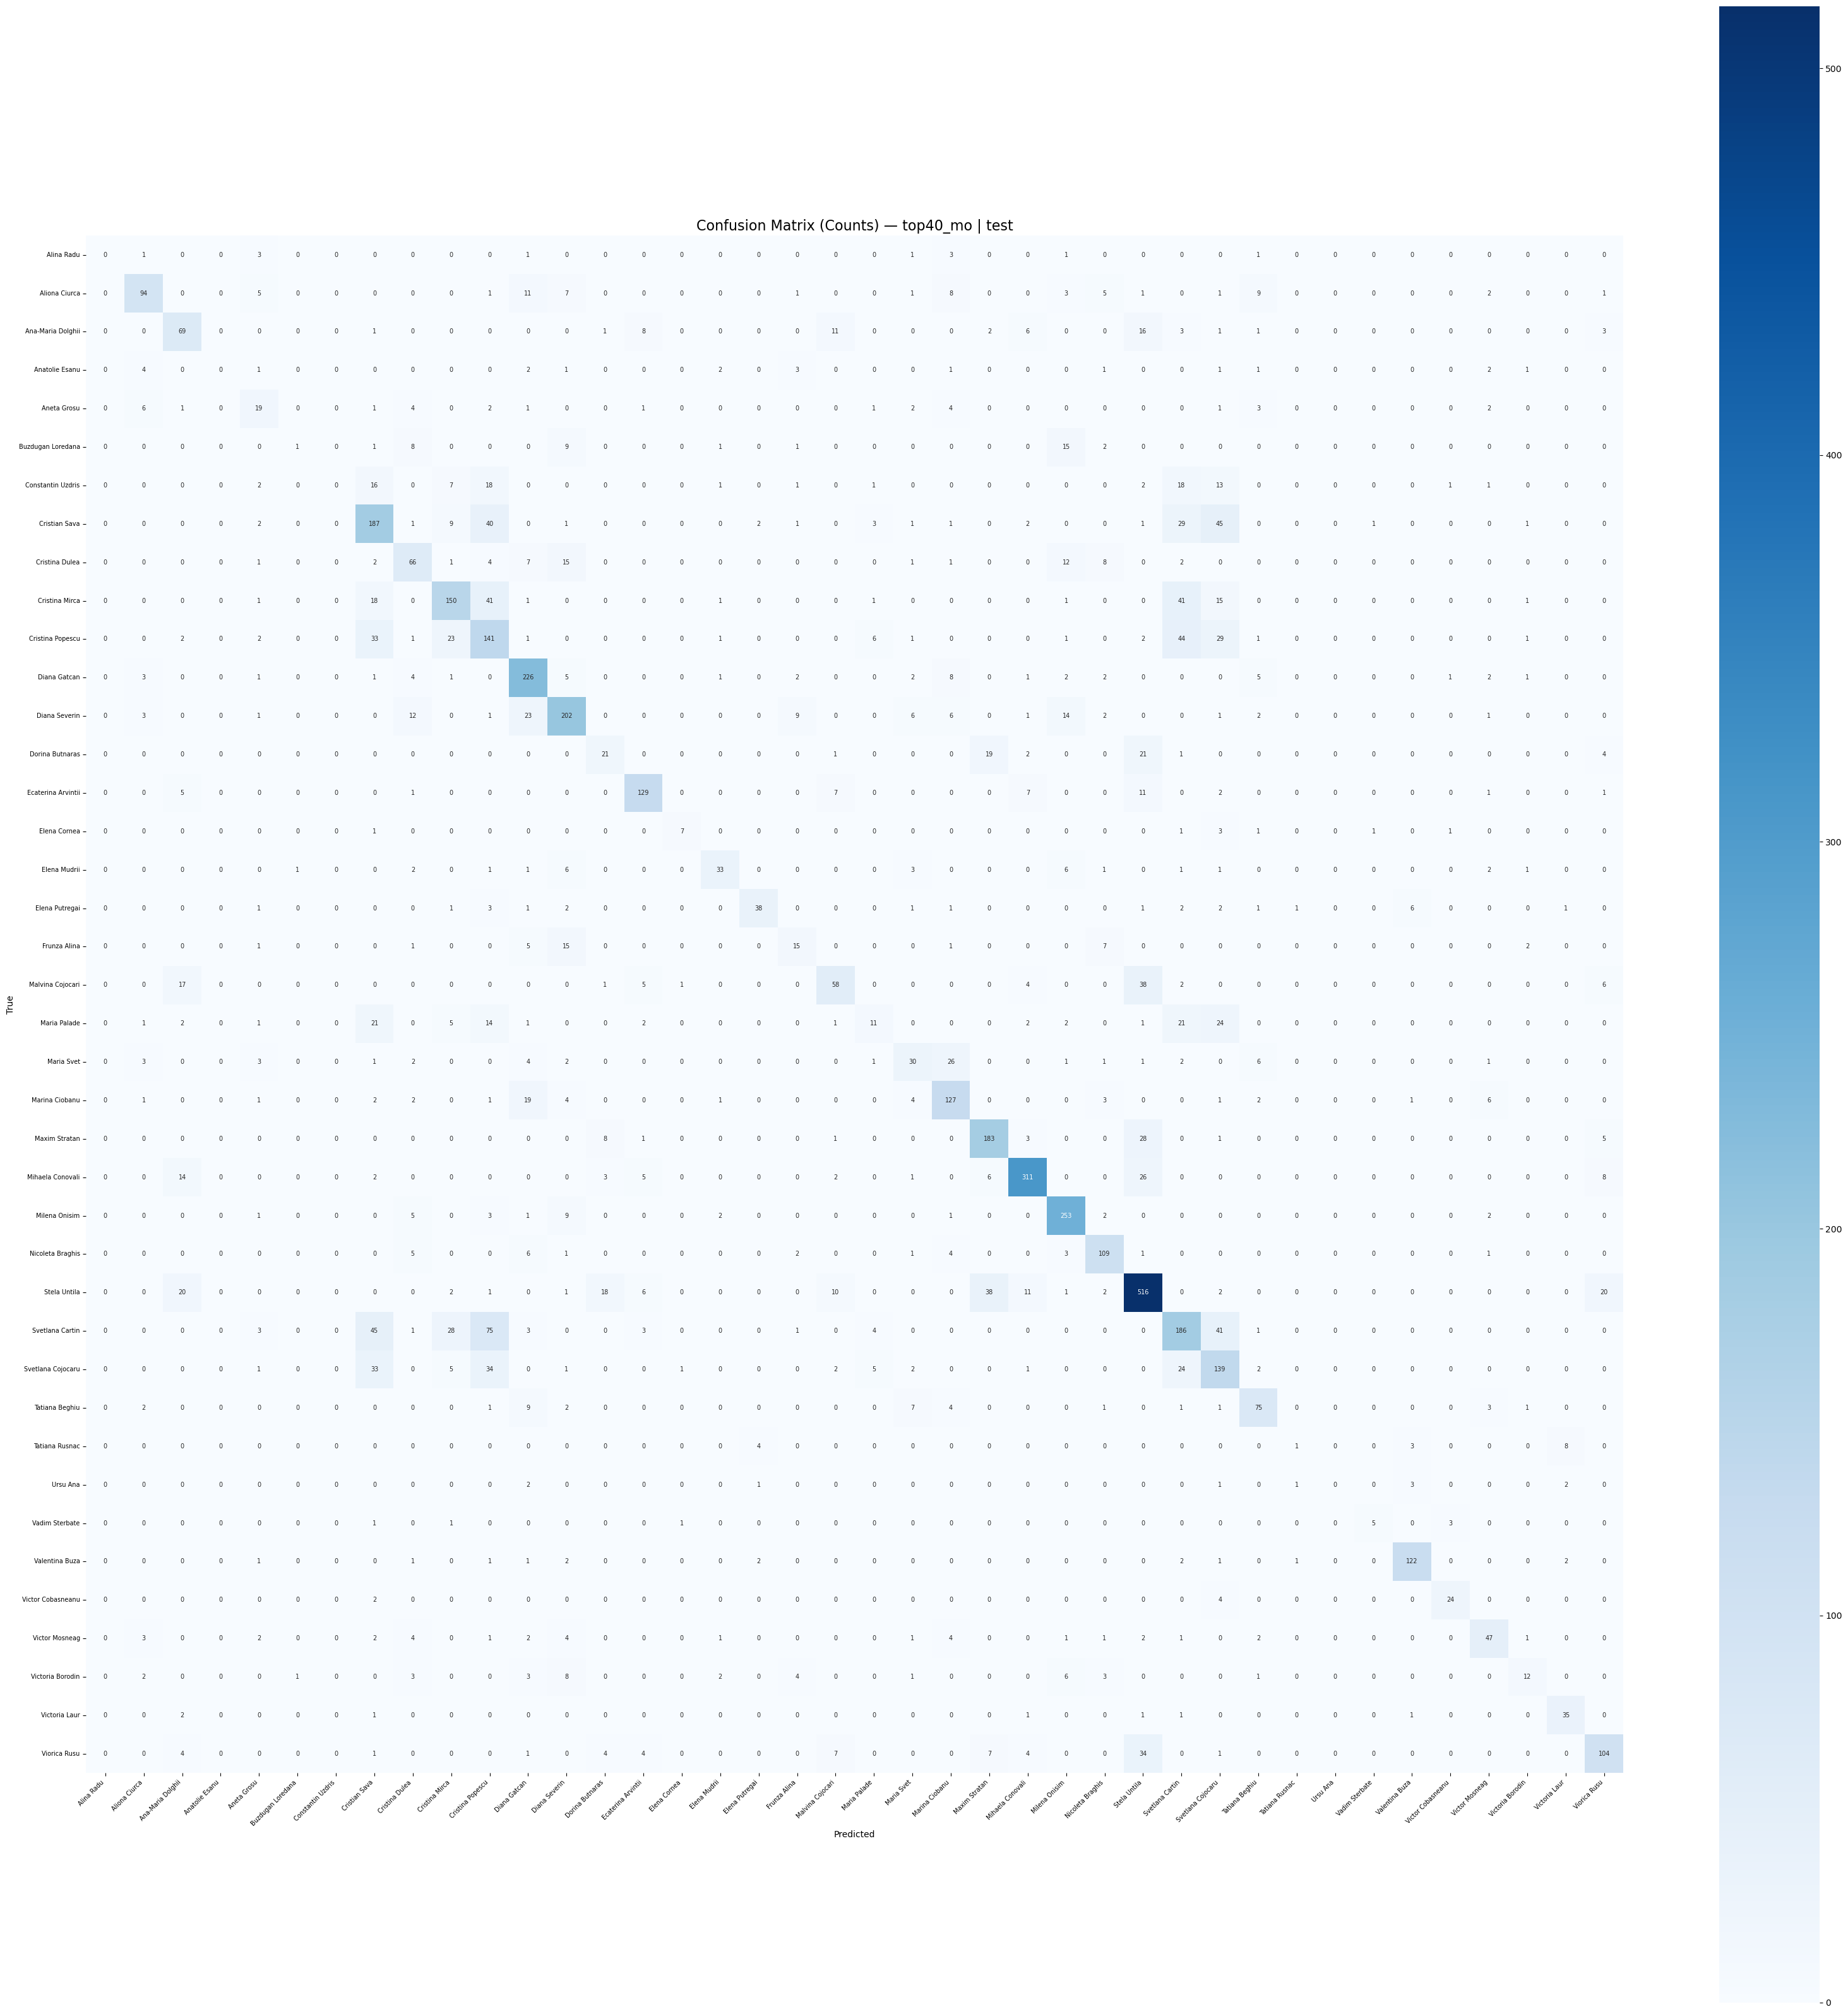

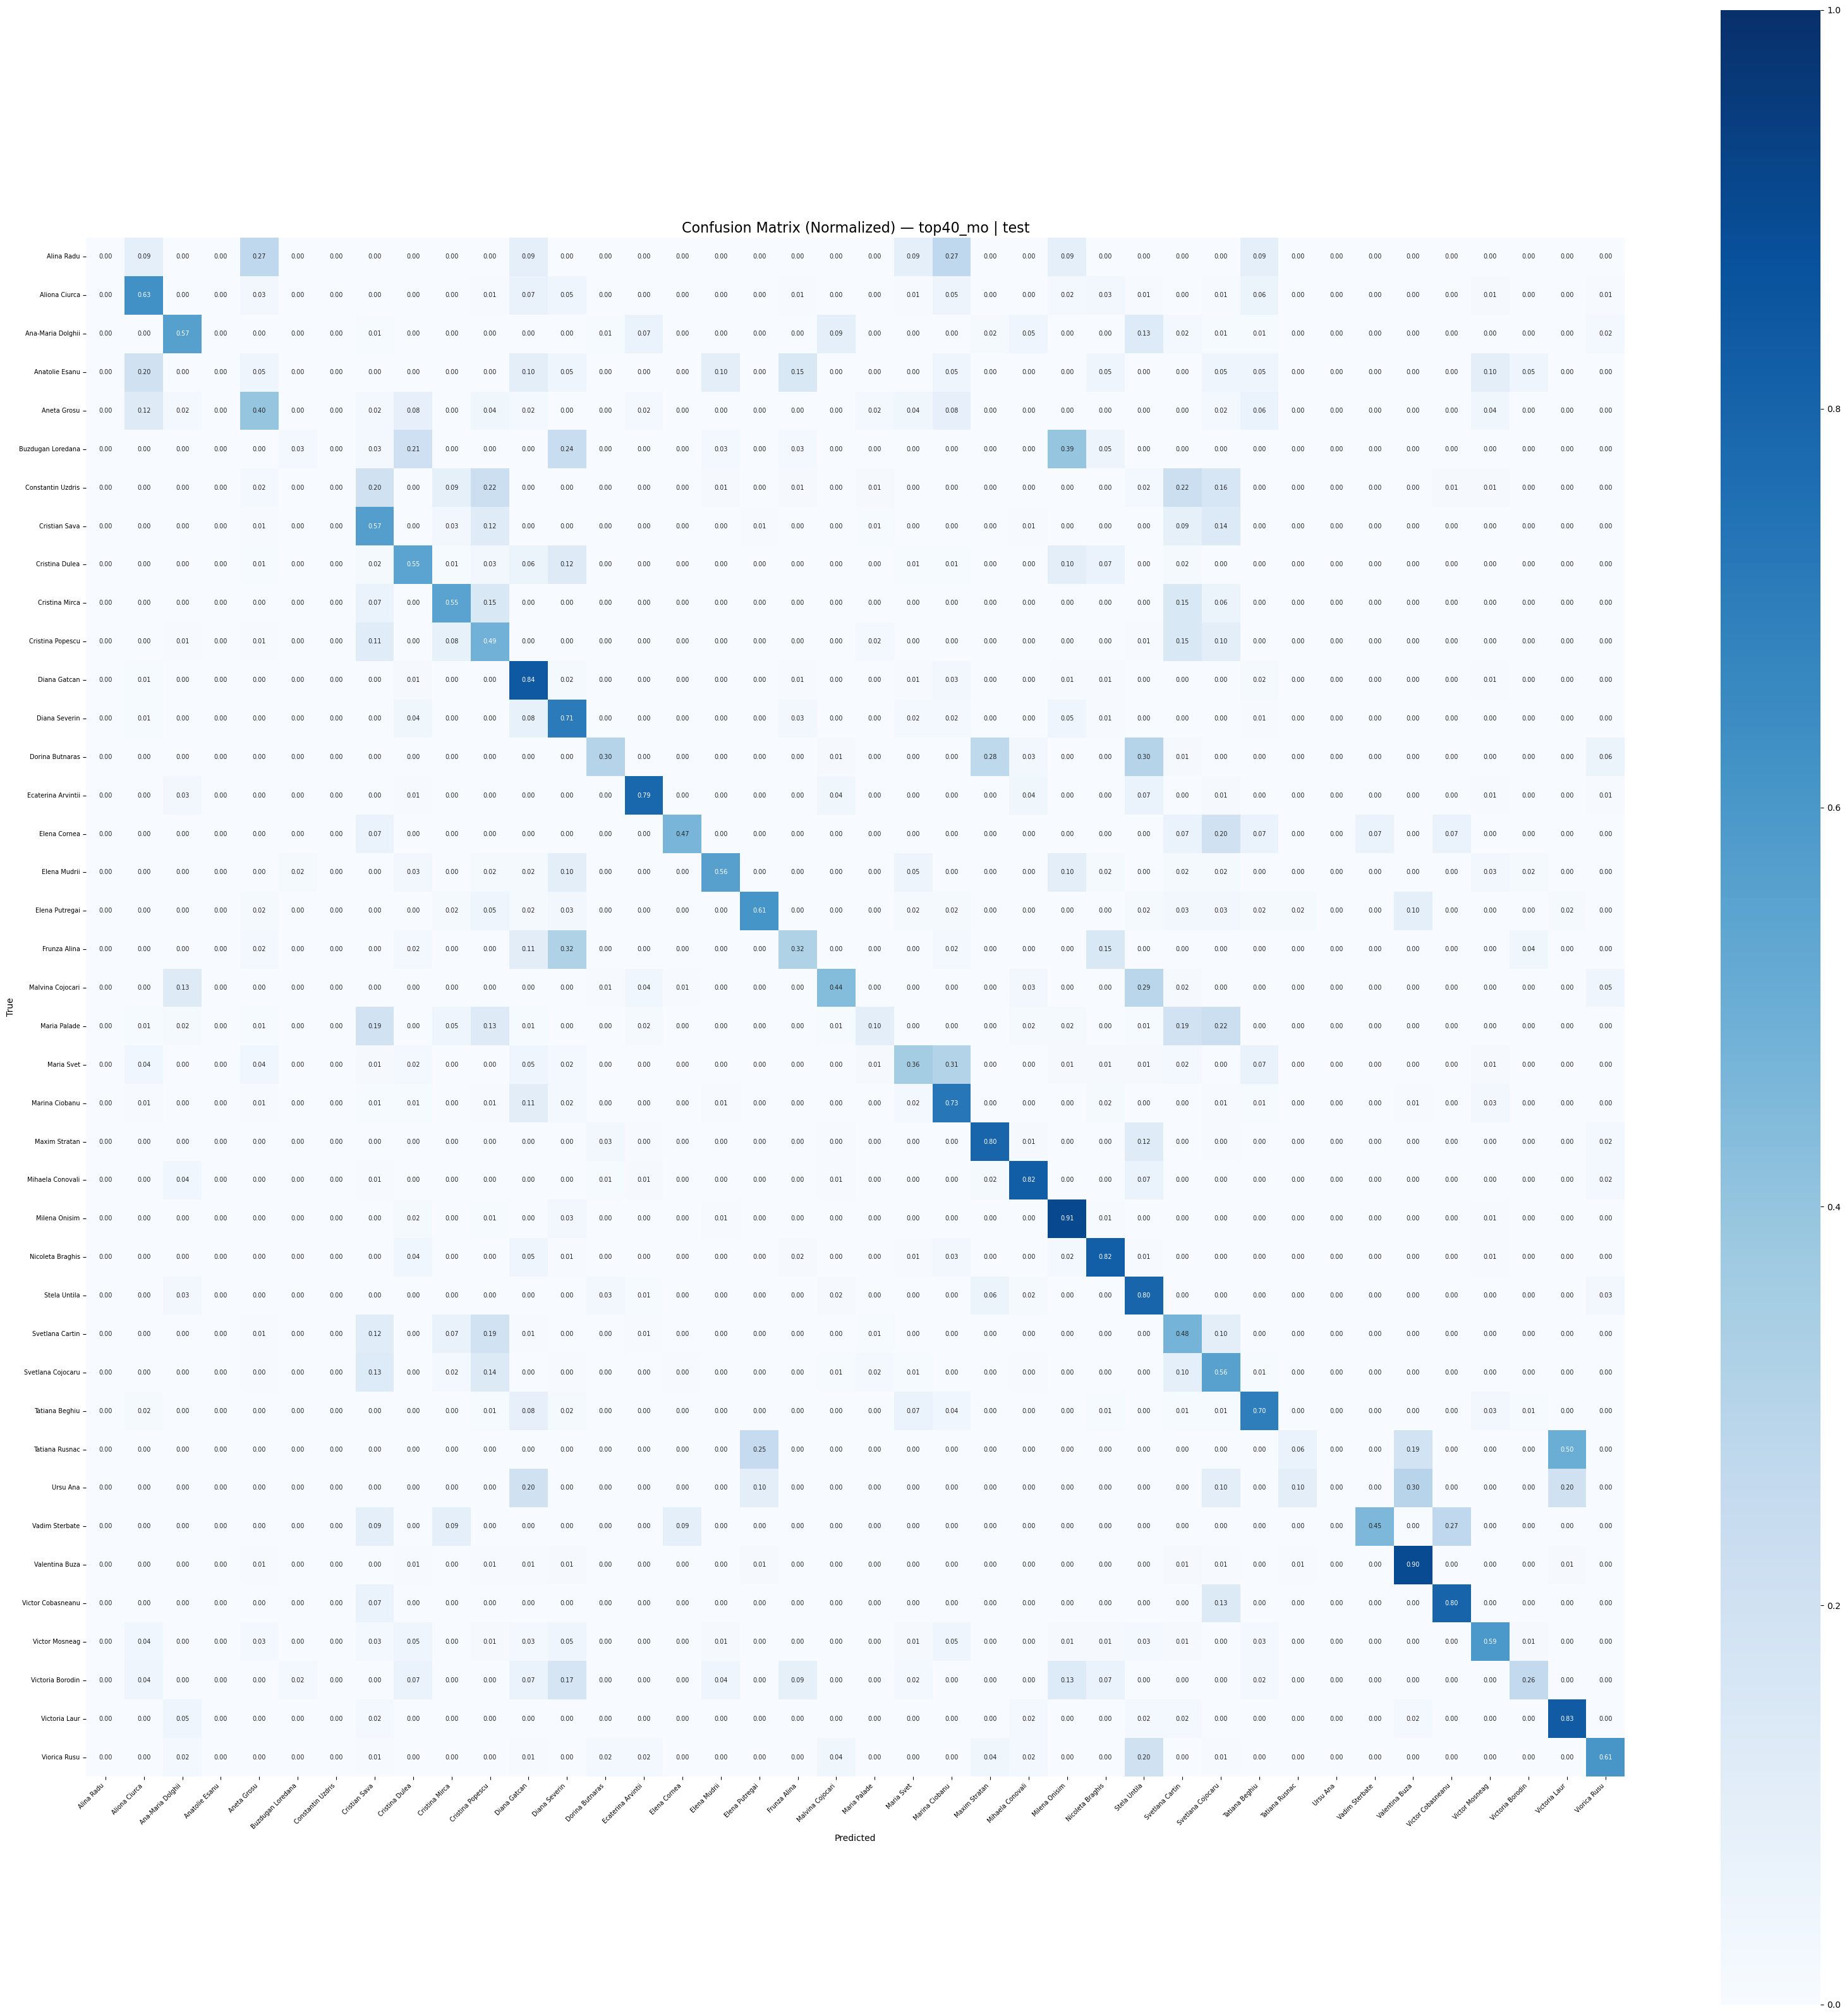

In [30]:
# confusion matrix
plot_confusion_matrix_bert_fusion(
    y_test40, test_preds_mo40, label_encoder40,
    dataset_name="top40_mo", split='test'
)

In [32]:
results = []

In [33]:
# append
results.append({
    'Experiment':  'BERT Fusion',
    'Dataset':     'top40_mo',
    'F1 Macro':    round(test_f1_mo40, 4),
    'Accuracy':    round(test_acc_mo40, 4),
    'Best Val F1': round(metrics_mo40['best_val_f1'], 4)
})

In [34]:
print(pd.DataFrame(results))

    Experiment   Dataset  F1 Macro  Accuracy  Best Val F1
0  BERT Fusion  top40_mo     0.516    0.6347       0.5084


In [79]:
# scriem in fisier
import json
json_path = 'results_fusion/results_fusion.json'
with open(json_path, 'r') as f:
    past_results = json.load(f)

past_results.append({
    'Experiment':  'BERT Fusion',
    'Dataset':     'top40_mo',
    'F1 Macro':    round(test_f1_mo40, 4),
    'Accuracy':    round(test_acc_mo40, 4),
    'Best Val F1': round(metrics_mo40['best_val_f1'], 4)
})

display(past_results)

[{'Experiment': 'BERT Fusion',
  'Dataset': 'top20_ro',
  'F1 Macro': 0.6256,
  'Accuracy': 0.6429,
  'Best Val F1': 0.6684},
 {'Experiment': 'BERT Fusion',
  'Dataset': 'top40_ro',
  'F1 Macro': 0.593,
  'Accuracy': 0.6076,
  'Best Val F1': 0.63},
 {'Experiment': 'BERT Fusion',
  'Dataset': 'top20_mo',
  'F1 Macro': 0.6789,
  'Accuracy': 0.6862,
  'Best Val F1': 0.687},
 {'Experiment': 'BERT Fusion',
  'Dataset': 'top40_mo',
  'F1 Macro': 0.5165,
  'Accuracy': 0.6166,
  'Best Val F1': 0.5266},
 {'Experiment': 'BERT Fusion',
  'Dataset': 'top40_mo',
  'F1 Macro': 0.5055,
  'Accuracy': np.float64(0.6076),
  'Best Val F1': 0.5367}]

In [80]:
with open(json_path, 'w') as f:
    json.dump(past_results, f, indent=2)

### Extragere Author Embeddings 
- nu se ruleaza train ci doar load la model si folosim clasificatorul final ca sa scoatem proiectiile (vectroii de dimensiune 128)

- functie auxiliara pentru convertire corecta in tensori

In [11]:
def to_float_tensor(x, device):
    # ma aasigur ca este citit ca tensor pe device
    if not torch.is_tensor(x):
        x = torch.tensor(x, dtype=torch.float32)
    else:
        x = x.float()
    return x.to(device)

- functie auxiliara care imparte pe ferestre un document.
- pastram ca si la contrastive `overlap` de 0.1 si `max_len` de 512

In [12]:
def split_into_windows(text, tokenizer, max_length=512, overlap=0.1):
    tokens = tokenizer.tokenize(text)
    # ok am scos tokenurile o sa fie ceva de genu : [CLS t1 t2 t3 SEP]
    special_tokens = 2 # [CLS] si [SEP]
    window_size = max_length - special_tokens # adica 510 de fapt
    stride = int(window_size * (1-overlap))

    # lista de ferestre
    windows = []
    for start in range(0, len(tokens), stride):
        end = start + window_size
        window_tokens = tokens[start:end]

        if len(window_tokens) == 0:
            continue

        window_text = tokenizer.convert_tokens_to_string(window_tokens) # uu nu stiam de asta
        windows.append(window_text)

        if end >= len(tokens):
            break # gata
    
    return windows

#### Caz 1: text scurt , sub 512 tokeni

text + stylo_features -> BERT(text) -> CLS -> stylo_network(stylo_features) -> concat(CLS, stylo_out) -> fusion layer -> embedding 128

In [13]:
def extract_fusion_embedding_batch(model, input_ids, attention_mask, stylo_features):
    model.eval()

    with torch.no_grad():
        bert_out = model.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls = bert_out.last_hidden_state[:, 0, :]
        cls = model.bert_dropout(cls)

        stylo_out = model.stylo_network(stylo_features)
        fused_input = torch.cat([cls, stylo_out], dim=1)
        fusion_embedding = model.fusion(fused_input)

    return fusion_embedding

#### Caz 2: text lung > 512 tokeni
- impartim in ferestre
- facem media CLS-urilor peste fiecare fereastra
- fuzionam cu stylo peste documentul intreg
- obtinem embeddingul de 128

In [14]:
def extract_fusion_embedding_long_document(model, text, stylo_features,
                                           tokenizer, device,
                                           max_length=512,
                                           overlap=0.1):
    """
    Pentru documente lungi:
    1. sparge textul in ferestre
    2. extrage CLS pentru fiecare fereastra
    3. face media CLS-urilor
    4. aplica stilometria globala a documentului
    5. aplica fusion o singura data
    """

    model.eval()

    windows = split_into_windows(
        text,
        tokenizer,
        max_length=max_length,
        overlap=overlap
    )

    cls_embeddings = []

    with torch.no_grad():
        for window in windows:
            encoded = tokenizer(
                window,
                max_length=max_length,
                truncation=True,
                padding="max_length",
                return_tensors="pt"
            )

            bert_out = model.bert(
                input_ids=encoded["input_ids"].to(device),
                attention_mask=encoded["attention_mask"].to(device)
            )

            cls = bert_out.last_hidden_state[:, 0, :]
            cls = model.bert_dropout(cls)

            cls_embeddings.append(cls.cpu())

        doc_cls = torch.cat(cls_embeddings, dim=0).mean(dim=0, keepdim=True)
        doc_cls = doc_cls.to(device)

        stylo_features = to_float_tensor(stylo_features, device)

        if stylo_features.dim() == 1:
            stylo_features = stylo_features.unsqueeze(0)

        stylo_out = model.stylo_network(stylo_features)

        fused_input = torch.cat([doc_cls, stylo_out], dim=1)

        fusion_embedding = model.fusion(fused_input)

    return fusion_embedding.squeeze(0).cpu()

### Construirea user embeddings (ma rog author embeddings)
- doar pe train
- autor A:
   - text1 → embedding 128
   - text2 → embedding 128
   - text3 → embedding 128

- user_embedding_A = media(text1, text2, text3)

In [15]:
def build_fusion_user_embeddings(model, texts, y, X_stylo,
                                 tokenizer, device, le,
                                 batch_size=32,
                                 max_length=512,
                                 use_windows=False,
                                 overlap=0.1):
    """
    Construieste cate un user embedding pentru fiecare autor.
    User embedding = media embedding-urilor textelor din train.
    """

    model.eval()
    author_embeddings = {}

    for author_idx, author_name in enumerate(le.classes_):
        indices = [
            i for i, label in enumerate(y)
            if label == author_idx
        ]

        embs = []

        if use_windows:
            for i in indices:
                emb = extract_fusion_embedding_long_document(
                    model=model,
                    text=texts[i],
                    stylo_features=X_stylo[i],
                    tokenizer=tokenizer,
                    device=device,
                    max_length=max_length,
                    overlap=overlap
                )

                embs.append(emb.unsqueeze(0))

        else:
            for start in range(0, len(indices), batch_size):
                batch_idx = indices[start:start + batch_size]

                batch_texts = [texts[i] for i in batch_idx]
                batch_stylo = to_float_tensor(X_stylo[batch_idx], device)

                encoded = tokenizer(
                    batch_texts,
                    max_length=max_length,
                    truncation=True,
                    padding="max_length",
                    return_tensors="pt"
                )

                emb = extract_fusion_embedding_batch(
                    model=model,
                    input_ids=encoded["input_ids"].to(device),
                    attention_mask=encoded["attention_mask"].to(device),
                    stylo_features=batch_stylo
                )

                embs.append(emb.cpu())

        all_embs = torch.cat(embs, dim=0)

        author_embeddings[author_name] = all_embs.mean(dim=0)

        print(f"{author_name}: {len(indices)} texte -> {author_embeddings[author_name].shape}")

    return author_embeddings

### Extragere document embeddings pentru test si val

- test_text1 → embedding 128
- test_text2 → embedding 128
- test_text3 → embedding 128

In [16]:
def extract_all_fusion_embeddings(model, texts, y, X_stylo,
                                  tokenizer, device,
                                  batch_size=32,
                                  max_length=512,
                                  use_windows=False,
                                  overlap=0.1):
    """
    Extrage embedding individual pentru fiecare document.
    Se foloseste pentru val/test.
    """

    model.eval()
    all_embs = []
    all_labels = []

    if use_windows:
        for i, text in enumerate(texts):
            emb = extract_fusion_embedding_long_document(
                model=model,
                text=text,
                stylo_features=X_stylo[i],
                tokenizer=tokenizer,
                device=device,
                max_length=max_length,
                overlap=overlap
            )

            all_embs.append(emb.unsqueeze(0))
            all_labels.append(y[i])

            if i % 100 == 0:
                print(f"{i}/{len(texts)}")

    else:
        for start in range(0, len(texts), batch_size):
            end = min(start + batch_size, len(texts))

            batch_texts = texts[start:end]
            batch_labels = y[start:end]
            batch_stylo = to_float_tensor(X_stylo[start:end], device)

            encoded = tokenizer(
                batch_texts,
                max_length=max_length,
                truncation=True,
                padding="max_length",
                return_tensors="pt"
            )

            emb = extract_fusion_embedding_batch(
                model=model,
                input_ids=encoded["input_ids"].to(device),
                attention_mask=encoded["attention_mask"].to(device),
                stylo_features=batch_stylo
            )

            all_embs.append(emb.cpu())
            all_labels.extend(batch_labels)

            if start % 1000 == 0:
                print(f"{start}/{len(texts)}")

    return torch.cat(all_embs, dim=0).numpy(), np.array(all_labels)

### Apelare pipeline de extragere embeddings

In [17]:
def run_fusion_embedding_analysis(model_path, train_loader, val_loader, test_loader, le, tokenizer, device, use_windows, overlap, dataset_name, output_dir):
    os.makedirs(output_dir, exist_ok=True)

    # extragem dataseturile prelucrate de functia de data loadere
    train_ds = train_loader.dataset
    val_ds = val_loader.dataset
    test_ds = test_loader.dataset

    # sanity check
    print(train_ds.__dict__.keys())
    # dict_keys(['texts', 'labels', 'stylo_features', 'tokenizer', 'max_length', 'stride'])
    # oricum sunt alea din clasa Dataset
    
    # scot textele?
    # le dam mai departe la functia care scoate embeddingurile
    texts_train = train_ds.texts
    texts_val = val_ds.texts
    texts_test = test_ds.texts

    # scoatem labels
    y_train = train_ds.labels
    y_val = val_ds.labels
    y_test = test_ds.labels

    # si stylo features pe care le bagam ca X
    x_train = train_ds.stylo_features
    x_val = val_ds.stylo_features
    x_test = test_ds.stylo_features

    num_labels = len(le.classes_)

    # instantiem modelul
    model = BERTWithStylometry(num_authors=num_labels, no_stylo_features=len(STYLO_FEATURES)).to(device)
    # si incarcam greutatile
    state_dict = torch.load(model_path, map_location=device)
    model.load_state_dict(state_dict)

    print(f"Model incarcat: {model_path}")
    
    # author embeddings din train
    print("\n=== Author Embeddings (train) ===")
    # pentru train
    author_embeddings = build_fusion_user_embeddings(
        model=model,
        texts=texts_train,
        y=y_train,
        X_stylo=x_train,
        tokenizer=tokenizer,
        device=device,
        le=le,
        use_windows=use_windows,
        overlap=overlap
        
    )

    # salvam in path
    author_emb_path = os.path.join(output_dir, f'fusion_user_emb_{dataset_name}.pt')

    torch.save({
        'author_embeddings': author_embeddings,
        'classes':           list(le.classes_),
        'num_authors':       num_labels,
        'dataset_name':      dataset_name,
        'model_path':        model_path,
        'use_windows':       use_windows
    }, author_emb_path)
    print(f"Author embeddings salvate: {author_emb_path}")

    # pentru val si test folosim doar extract fusion embeddings adica nu facem media documentelor
    # doc embeddings din val
    print("\n=== Doc Embeddings (val) ===")
    val_embs, val_labels = extract_all_fusion_embeddings(
        model=model,
        texts=texts_val,
        y=y_val,
        X_stylo=x_val,
        tokenizer=tokenizer,
        device=device,
        use_windows=use_windows,
        overlap=overlap
    )
    
    print("\n=== Doc Embeddings (test) ===")
    test_embs, test_labels = extract_all_fusion_embeddings(
        model=model,
        texts=texts_test,
        y=y_test,
        X_stylo=x_test,
        tokenizer=tokenizer,
        device=device,
        use_windows=use_windows,
        overlap=overlap
    )

    # salveaza doc embeddings
    np.savez(
        os.path.join(output_dir, f'fusion_val_emb_{dataset_name}.npz'),
        embeddings=val_embs, labels=val_labels
    )
    np.savez(
        os.path.join(output_dir, f'fusion_test_emb_{dataset_name}.npz'),
        embeddings=test_embs, labels=test_labels
    )
    print(f"Doc embeddings salvate.")
    
    return author_embeddings, val_embs, val_labels, test_embs, test_labels


Romania top 20

In [18]:
user_embs, val_embs, val_labels, test_embs, test_labels = \
    run_fusion_embedding_analysis(
        model_path='best_model_fusion_top20_ro.pt',
        train_loader=train_loader_ro20,
        val_loader=val_loader_ro20,
        test_loader=test_loader_ro20,
        le=label_encoder,
        tokenizer=tokenizer,
        device=device,
        dataset_name='top20_ro',
        output_dir='outputs_fusion/top20_ro',
        use_windows=True,
        overlap=0.1
    )

dict_keys(['texts', 'labels', 'stylo_features', 'tokenizer', 'max_length', 'stride'])


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: best_model_fusion_top20_ro.pt

=== Author Embeddings (train) ===
Adrian Dumitru: 2673 texte -> torch.Size([128])
Alexandra Andronie: 2147 texte -> torch.Size([128])
Alexandru Costea: 3390 texte -> torch.Size([128])
Alexandru Toader: 1292 texte -> torch.Size([128])
Alina Manaila: 1450 texte -> torch.Size([128])
Alina Popescu: 1832 texte -> torch.Size([128])
Andrada Giubega: 1621 texte -> torch.Size([128])
Andreea Tobias: 1167 texte -> torch.Size([128])
Bogdan Pacurar: 3873 texte -> torch.Size([128])
Daniela Chihaia: 1655 texte -> torch.Size([128])
Diana Nechita: 3765 texte -> torch.Size([128])
Georgiana Marina: 4043 texte -> torch.Size([128])
Ioana Coman: 2471 texte -> torch.Size([128])
Liviu Cojan: 4719 texte -> torch.Size([128])
Luana Pavaluca: 3258 texte -> torch.Size([128])
Marco Badea: 1223 texte -> torch.Size([128])
Mihnea Lazar: 1115 texte -> torch.Size([128])
Monica Bonea: 4137 texte -> torch.Size([128])
Robert Kiss: 2400 texte -> torch.Size([128])
Vlad Mironescu

Moldova top 20

In [21]:
user_embs_mo20, val_embs_mo20, val_labels_mo20, test_embs_mo20, test_labels_mo20 = \
    run_fusion_embedding_analysis(
        model_path='best_model_fusion_top20_mo.pt',
        train_loader=train_loader_mo20,
        val_loader=val_loader_mo20,
        test_loader=test_loader_mo20,
        le=label_encoder20,
        tokenizer=tokenizer,
        device=device,
        dataset_name='top20_mo',
        output_dir='outputs_fusion/top20_mo',
        use_windows=True,
        overlap=0.1
    )

dict_keys(['texts', 'labels', 'stylo_features', 'tokenizer', 'max_length', 'stride'])


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: best_model_fusion_top20_mo.pt

=== Author Embeddings (train) ===
Aliona Ciurca: 1206 texte -> torch.Size([128])
Ana-Maria Dolghii: 971 texte -> torch.Size([128])
Cristian Sava: 2620 texte -> torch.Size([128])
Cristina Dulea: 958 texte -> torch.Size([128])
Cristina Mirca: 2168 texte -> torch.Size([128])
Cristina Popescu: 2306 texte -> torch.Size([128])
Diana Gatcan: 2146 texte -> torch.Size([128])
Diana Severin: 2272 texte -> torch.Size([128])
Ecaterina Arvintii: 1313 texte -> torch.Size([128])
Malvina Cojocari: 1051 texte -> torch.Size([128])
Marina Ciobanu: 1401 texte -> torch.Size([128])
Maxim Stratan: 1840 texte -> torch.Size([128])
Mihaela Conovali: 3028 texte -> torch.Size([128])
Milena Onisim: 2228 texte -> torch.Size([128])
Nicoleta Braghis: 1065 texte -> torch.Size([128])
Stela Untila: 5186 texte -> torch.Size([128])
Svetlana Cartin: 3126 texte -> torch.Size([128])
Svetlana Cojocaru: 1998 texte -> torch.Size([128])
Valentina Buza: 1086 texte -> torch.Size([128])

Romania top 40

In [24]:
# vezi ca am numit din greseala label encoder 40 la ambele top 40 deci te duci ictesti ruezi dataloaderele de fiecare data
user_embs_ro40, val_embs_ro40, val_labels_ro40, test_embs_ro40, test_labels_ro40 = \
    run_fusion_embedding_analysis(
        model_path='best_model_fusion_top40_ro.pt',
        train_loader=train_loader_ro40,
        val_loader=val_loader_ro40,
        test_loader=test_loader_ro40,
        le=label_encoder40,
        tokenizer=tokenizer,
        device=device,
        dataset_name='top40_ro',
        output_dir='outputs_fusion/top40_ro',
        use_windows=True,
        overlap=0.1
    )
# 37 min

dict_keys(['texts', 'labels', 'stylo_features', 'tokenizer', 'max_length', 'stride'])


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: best_model_fusion_top40_ro.pt

=== Author Embeddings (train) ===
Adrian Dumitru: 2673 texte -> torch.Size([128])
Alexandra Andronie: 2147 texte -> torch.Size([128])
Alexandru Costea: 3390 texte -> torch.Size([128])
Alexandru Toader: 1292 texte -> torch.Size([128])
Alina Manaila: 1450 texte -> torch.Size([128])
Alina Popescu: 1832 texte -> torch.Size([128])
Ana Petrescu: 920 texte -> torch.Size([128])
Anca Dumitrescu: 790 texte -> torch.Size([128])
Andrada Giubega: 1621 texte -> torch.Size([128])
Andreea Neblea: 836 texte -> torch.Size([128])
Andreea Tobias: 1167 texte -> torch.Size([128])
Bogdan Pacurar: 3873 texte -> torch.Size([128])
Carmen Zanfir: 1101 texte -> torch.Size([128])
Catalin Costache: 878 texte -> torch.Size([128])
Cosmin Pirv: 947 texte -> torch.Size([128])
Cristian Anton: 829 texte -> torch.Size([128])
Cristian Matei: 1006 texte -> torch.Size([128])
Dan Duca: 668 texte -> torch.Size([128])
Daniela Chihaia: 1655 texte -> torch.Size([128])
Diana Nechita: 

Moldova top 40

In [ ]:
# avem grija la label encoder
user_embs_mo40, val_embs_mo40, val_labels_mo40, test_embs_mo40, test_labels_mo40 = \
    run_fusion_embedding_analysis(
        model_path='best_model_fusion_top40_mo.pt',
        train_loader=train_loader_mo40,
        val_loader=val_loader_mo40,
        test_loader=test_loader_mo40,
        le=label_encoder40,
        tokenizer=tokenizer,
        device=device,
        dataset_name='top40_mo',
        output_dir='outputs_fusion/top40_mo',
        use_windows=True,
        overlap=0.1
    )
# 30 minute

dict_keys(['texts', 'labels', 'stylo_features', 'tokenizer', 'max_length', 'stride'])


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: best_model_fusion_top40_mo.pt

=== Author Embeddings (train) ===
Alina Radu: 93 texte -> torch.Size([128])
Aliona Ciurca: 1206 texte -> torch.Size([128])
Ana-Maria Dolghii: 971 texte -> torch.Size([128])
Anatolie Esanu: 160 texte -> torch.Size([128])
Aneta Grosu: 387 texte -> torch.Size([128])
Buzdugan Loredana: 306 texte -> torch.Size([128])
Constantin Uzdris: 646 texte -> torch.Size([128])
Cristian Sava: 2620 texte -> torch.Size([128])
Cristina Dulea: 958 texte -> torch.Size([128])
Cristina Mirca: 2168 texte -> torch.Size([128])
Cristina Popescu: 2306 texte -> torch.Size([128])
Diana Gatcan: 2146 texte -> torch.Size([128])
Diana Severin: 2272 texte -> torch.Size([128])
Dorina Butnaras: 553 texte -> torch.Size([128])
Ecaterina Arvintii: 1313 texte -> torch.Size([128])
Elena Cornea: 117 texte -> torch.Size([128])
Elena Mudrii: 472 texte -> torch.Size([128])
Elena Putregai: 496 texte -> torch.Size([128])
Frunza Alina: 379 texte -> torch.Size([128])
Malvina Cojocari: 1051